# 09 Credit feedback: does the required credit, fed back as a real credit, deliver the target?

**Purpose.** Notebook 07 derives a required investment tax credit (ITC) rate from the shadow price
of the nuclear capacity mandate. The *shadow price* (the dual) is the marginal system cost of one
more MW of mandated nuclear capacity in a solve year. This notebook closes the loop. It reads two
batches of ReEDS runs in which the derived rate enters the model as an actual tax credit and the
mandate is removed, and it asks whether the model then builds what the mandate built. Section A
reads the 19 `itcfb` runs: five arms that separate the credit mechanics from the learning
economics and give the per-world verdict. Section B reads the 24 `itcfbm` runs (the *minus probe*):
rates 1, 5, 10 and 15 points below the headline rate, which bracket the lowest uniform rate that
still delivers the target. The two sections together give Supplementary Figs. 11 and 12,
Supplementary Table 3 and the numbers of Supplementary Note 7. The ignition-cushion table `r05`
is the basis of the three-point display allowance that notebook 10 applies to the credit-rate
figures.

**Inputs.**
- `results/extracts/{itcfb,itcfbm,smr100}/{cap,cap_new_ann,nuclear_cap_price}.parquet`
  (notebook 05_extract_reeds_outputs). No `outputs.h5` file is opened.
- `results/exports/06a/itcfb_checks/{checks_summary, duals_by_year, trajectory_gaps,
  fbK_calibration, fbA_collapse, incentives_echo}.csv` and
  `results/exports/06a/itcfbm_checks/{checks_summary, trajectory_gaps, delivery_outcomes,
  incentives_echo}.csv` (notebook 06a_run_tables_core).
- `results/exports/07/t09_required_itc.csv` (notebook 07_required_support): the headline rate
  `i_model_headline` by world and rate year.
- `data/reeds_inputs/budget_parity_context.csv` (frozen design record of the minus-probe ladder).
- Casefiles `cases_nuclearlearning_{itcfb,itcfbm}.csv` at the repository root; ReEDS inputs of
  this fork: `inputs/financials/{deflator, incentives_obbba_itcfb_*_p50, incentives_obbba_itcfbm*_p50}.csv`,
  `inputs/nuclear_learning/nuclear_cap_trajectory_*_smr.csv`.

**Outputs.**
- `results/exports/09/itcfb/`: `fed_rate_echo.csv`, `q00_run_inventory`, `q01_fbA_dual_collapse`,
  `q02_fbB_gaps`, `q03_fbC_gaps`, `q04_s9_verdict`, `q05_fbK_calibration`, `q06_rate_deployment`,
  `q07_large_substitution` (CSV); the panels `h03_fbC_trajectory_panels.png`,
  `h04_delivery_summary.png`, `h06_deployment_vs_rate.png`.
- `results/exports/09/itcfbm/`: `fed_rate_echo.csv`, `r00_run_inventory`, `r01_rate_ladder`,
  `r02_delivery_gaps`, `r03_minimality_verdicts`, `r04_rate_deployment`, `r05_ignition_cushion`,
  `r06_substitution` (CSV); the panel `j06_new_nuclear_cliff.png`.
- `results/figures/si/SF11_closed_loop_delivery.png` (h04 over h03) and
  `results/figures/si/SF12_cliff_and_demand_curve.png` (j06 over h06).

**Paper items.** Supplementary Fig. 11 (h04, h03), Supplementary Fig. 12 (j06, h06),
Supplementary Table 3 (a = `q04`, b = `q06`, c = `r03`, d = `r04`; notebook 16 formats them),
Supplementary Note 7 (`q04`, `q06`, `r02`, `r03`, `r04`, `r05`).

**Runtime.** About 15 seconds on this machine (extracts only).

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4)

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': None}

## 1. The closed-loop idea, the runs and the conventions

**The closed loop.** Notebook 07 turns each mandate run's shadow price into a required credit
rate per rate year. That derivation assumes the model responds to a credit exactly as it responds
to the mandate. The feedback runs test the assumption directly: each run takes the derived rate
schedule of one world, writes it into a ReEDS incentives file as a real ITC on new SMR capacity,
switches the mandate off, and re-solves. If the credit carries the full value of the shadow price,
national SMR capacity should reach the mandated *target trajectory* (the national path of mandated
SMR capacity from one published source; `eia`, `aj`, `iaea`, `mck`, `cop28`, `eo` in the code,
ordered by 2050 ambition). Each world here is the P50 *cost sample* (the median joint Monte Carlo
draw of the cost world) of its trajectory.

**The fed rate.** The rate written to the file is the paper's headline rate `i_model_headline`
(from t09) plus a 0.01 *indifference bump*. The bump breaks the tie at which a builder is exactly
indifferent between building and not building. ReEDS applies the credit inside the finance
multiplier with a 10% tax-equity haircut (the `penalty` 0.1), so the rate a project actually
receives, the *monetized* rate, is 0.9 times the file rate.

**The two rate bases.** The paper quotes credit rates on two bases, and the figures of this
notebook use both. The *statutory* rate is the rate written in law and in the incentives file.
The *monetized* rate is the value the project receives after the haircut, so it is 0.9 times the
statutory rate. SF12a plots the statutory basis; SF12b and the `m_monetized` columns use the
monetized basis. The two axes should not be read across.

**The five arms of the `itcfb` batch.** Each arm is one row of controls.

| Arm | Mandate | Credit | Learning | Role |
|---|---|---|---|---|
| fbA | on | fed rate | frozen | Misapplication control: with the credit added, every previously binding shadow price must collapse to about zero. |
| fbB | off | fed rate | frozen | Convex control: without learning the model is a linear program, so the derived credit should reproduce the trajectory. |
| fbC | off | fed rate | draw-calibrated | The test itself: the same credit with endogenous learning on. |
| fbK | on | none | draw-calibrated | Engine calibration: the in-run learned cost path must reproduce the drawn P50 cost path. |
| fbR | off | flat 0, 30, 50% (both nuclear technologies) | frozen | Demand-curve anchors in the `eia` world. |

*Learning frozen* means the plant costs follow the drawn cost path as fixed inputs. *Draw-calibrated
endogenous learning* means the learning engine inside ReEDS computes the cost of each solve year
from the capacity the model itself has built, with the learning parameters of the P50 draw. Under
endogenous learning the problem is no longer convex: cheaper later builds depend on earlier builds,
so a marginal price such as a credit can in principle fail to reproduce a quantity target. The fbB
arm isolates the mechanics; the fbC arm adds the economics.

**Exclusions by design.** The P95 worlds are not run, because their required rate exceeds 100% in
late rate years and an ITC alone cannot deliver them. The large-reactor comparators are not run,
because their early shadow prices price the retention of the existing fleet, which a credit on new
builds cannot buy.

**The reader.** `cap(case)` and friends below read the parquet extracts of notebook 05. The
extracts keep the nuclear rows of `cap` and `cap_new_ann` by region, with the row order of the
`outputs.h5` table, so the national sums reproduce the original analysis.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

pd.set_option("display.width", 220)

EXP_A = paths.exports("09") / "itcfb"          # section A exports and panels
EXP_B = paths.exports("09") / "itcfbm"         # section B exports and panels
EXP_A.mkdir(exist_ok=True)
EXP_B.mkdir(exist_ok=True)
CHECKSFB = paths.require(paths.exports("06a") / "itcfb_checks", "notebook 06a_run_tables_core")
CHECKSM = paths.require(paths.exports("06a") / "itcfbm_checks", "notebook 06a_run_tables_core")
INPUTS = paths.reeds_inputs()
FIN_DIR = INPUTS / "financials"

# ---- case matrices -------------------------------------------------------------------
cases_fb = pd.read_csv(paths.casefile("itcfb"), index_col=0)
CASES = [c for c in cases_fb.columns if c != "Default Value"]
assert len(CASES) == 19, f"the itcfb batch holds 19 runs (2 fbA, 6 fbB, 6 fbC, 2 fbK, 3 fbR): {CASES}"

cases_m = pd.read_csv(paths.casefile("itcfbm"), index_col=0)
CASES_M = [c for c in cases_m.columns if c != "Default Value"]
assert len(CASES_M) == 24, f"the itcfbm batch holds 24 runs (2 arms x 4 rungs x 3 worlds): {CASES_M}"

def sw(csv_, case, name):
    # One switch value of one case; an empty cell uses the default value.
    v = csv_.loc[name, case]
    if pd.isna(v) or str(v).strip() == "":
        v = csv_.loc[name, "Default Value"]
    return "" if pd.isna(v) else str(v).strip()

SCHEDULES = ["eia", "aj", "iaea", "mck", "cop28", "eo"]      # ordered by 2050 ambition
assert SCHEDULES == ps.SCHED_ORDER, "schedule tokens diverged from plotstyle.SCHED_ORDER"

def parse_case(c):
    parts = c.split("_")
    arm = parts[0]
    world = parts[1] if arm != "fbR" else "eia"
    return arm, world

META = {c: dict(arm=parse_case(c)[0], world=parse_case(c)[1],
                mandate=int(float(sw(cases_fb, c, "GSw_NuclearCapMandate"))),
                learning=int(float(sw(cases_fb, c, "GSw_NuclearLearning"))))
        for c in CASES}
ARM_CASES = {a: [c for c in CASES if META[c]["arm"] == a]
             for a in ["fbA", "fbB", "fbC", "fbK", "fbR"]}
BASE_OF_WORLD = {w: f"smr100_{w}_p50" for w in SCHEDULES}

# ---- house style (plotstyle is the label and colour authority) ----------------------
COL = ps.COL
INK, MUTED = ps.INK, ps.MUTED
SCHED_C = dict(ps.SCHED_C)
SCHED_LABEL = dict(ps.SCHED_LABEL)
# The Supplementary document places each figure 6.5 in wide, so type is authored for the width
# of the COMPOSED item: SF11 (h04 over h03) is 11.71 in wide, SF12 (j06 over h06) 6.67 in.
# plotstyle.fonts(cw) converts the printed type specification to the points to draw at.
CW_SF11, CW_SF12 = 11.71, 6.67
F_SF11, F_SF12 = ps.fonts(CW_SF11), ps.fonts(CW_SF12)

# ---- dollar conventions -----------------------------------------------------------------
# ReEDS reports 2004 dollars. The deflator table gives the 2022 -> 2004 factor; 1/Deflator(2024)
# converts 2004 dollars to 2024 dollars (the `_2024` export columns).
DEFL = pd.read_csv(paths.deflator_path())
DEFL.columns = ["t", "Deflator"]
DEFL = DEFL.set_index("t")["Deflator"]
D2022 = float(DEFL.loc[2022])
TO2024 = 1.0 / float(DEFL.loc[2024])

# ---- target trajectories --------------------------------------------------------------
NL_DIR = INPUTS / "nuclear_learning"

def trajectory(scen):
    tr = pd.read_csv(NL_DIR / f"nuclear_cap_trajectory_{scen}.csv")
    tr.columns = [c.lstrip("*") for c in tr.columns]
    return tr.set_index(tr.columns[0])["MW"]

TRAJ = {w: trajectory(f)
        for w, f in [("eia", "eia_aeo_high_smr"), ("aj", "abou_jaoude_smr"),
                     ("iaea", "iaea_high_smr"), ("mck", "mckinsey_smr"),
                     ("cop28", "cop28_smr"), ("eo", "eo2025_smr")]}

# ---- national capacity series from the extracts (both batches + the six base runs) ----
def national(batch, key, tech, t_min=None):
    df = h5io.load(batch, key)
    df = df[df["i"] == tech]
    if t_min is not None:
        df = df[df["t"] > t_min]
    return {c: g.groupby("t")["Value"].sum() for c, g in df.groupby("case", sort=False)}

SMR_CAP, LG_CAP, LG_NEW = {}, {}, {}
for batch in ["itcfb", "itcfbm"]:
    SMR_CAP.update(national(batch, "cap", "nuclear-smr"))
    LG_CAP.update(national(batch, "cap", "nuclear"))
    LG_NEW.update(national(batch, "cap_new_ann", "nuclear", t_min=2030))
_lg_base = national("smr100", "cap", "nuclear")
for w in SCHEDULES:                          # base-run large fleet: substitution baseline
    LG_CAP[BASE_OF_WORLD[w]] = _lg_base[BASE_OF_WORLD[w]]
EMPTY = pd.Series(dtype=float)               # ReEDS drops all-zero tables: a missing series is zero
for c in CASES + CASES_M:
    for d_ in (SMR_CAP, LG_CAP, LG_NEW):
        d_.setdefault(c, EMPTY)
print(f"capacity series: {len(CASES)} itcfb runs, {len(CASES_M)} itcfbm runs, "
      f"{len(SCHEDULES)} base runs (large fleet)")

capacity series: 19 itcfb runs, 24 itcfbm runs, 6 base runs (large fleet)


## 2. The fed rates: the incentives files against the t09 headline rate

Notebook 06a reads the rates the runs actually received from the incentives files
(`inputs/financials/incentives_obbba_itcfb*_p50.csv`), because those files are the ground truth
of what the model saw. 06a cannot compare them with the headline rate, because the headline rate
table t09 comes from notebook 07, which runs after 06a. This cell does that comparison.

It rebuilds the expected file rate from t09 with the two rules that wrote the files:
`round(i_model_headline + 0.01, 3)` for the main `itcfb` set and `round(i_model_headline - d, 3)`
for the minus set, with the decrement `d` = 0.01, 0.05, 0.10 or 0.15. It then asserts three things.
The rate echo of 06a equals the expected rate in every (world, rung, year). The six main files and
the twelve minus files equal the t09 schedule at exactly the t09 rate years, credit Nuclear-SMR
only, and follow the credit conventions (safe harbor 0, online year equal to the construction-start
year, penalty 0.1, no bonuses). The rate years that 06a took from the files, which label each
trajectory-gap row `rate` or `slack`, are the t09 rate years. A *rate year* is a solve year in
which the mandate binds in the base run, so t09 derives a rate for it; a *slack year* has no
binding mandate and gets no credit.

`fed_rate_echo.csv` in each export folder restores the `itc_frac_expected` column next to the file
rate.

In [3]:
t09 = pd.read_csv(paths.require(paths.exports("07") / "t09_required_itc.csv",
                                "notebook 07_required_support"),
                  usecols=["case", "t", "status", "i_model_headline"])
EPS, PEN = 0.01, 0.1                          # indifference bump; tax-equity haircut
DECS = {"m01": 0.01, "m05": 0.05, "m10": 0.10, "m15": 0.15}
HEAD = {}                                     # world -> {t: i_model_headline}
for w in SCHEDULES:
    sub = t09[(t09["case"] == BASE_OF_WORLD[w]) & (t09["status"] == "rate")]
    assert len(sub) and sub["i_model_headline"].notna().all(), f"t09 has no rate years for {w}"
    HEAD[w] = {int(t): float(i) for t, i in zip(sub["t"], sub["i_model_headline"])}
FILE_FB = {w: {t: round(i + EPS, 3) for t, i in HEAD[w].items()} for w in SCHEDULES}
FILE_M = {(w, g): {t: round(i - d, 3) for t, i in HEAD[w].items()}
          for w in ["aj", "mck", "eo"] for g, d in DECS.items()}

# ---- (i) the 06a echo equals the expected rate in every row ---------------------------
def echo_with_expected(echo, expected, keys):
    rows = []
    for k, exp_ in expected.items():
        kk = k if isinstance(k, tuple) else (k,)
        sub = echo
        for col, val in zip(keys, kk):
            sub = sub[sub[col] == val]
        got = dict(zip(sub["t"].astype(int), sub["itc_frac_file"]))
        for t in sorted(set(got) | set(exp_)):
            rows.append(dict(zip(keys, kk), t=t, itc_frac_file=got.get(t),
                             itc_frac_expected=exp_.get(t)))
    return pd.DataFrame(rows)

ECHO_FB = echo_with_expected(pd.read_csv(CHECKSFB / "incentives_echo.csv"), FILE_FB, ["world"])
ECHO_M = echo_with_expected(pd.read_csv(CHECKSM / "incentives_echo.csv"),
                            {k: FILE_M[k] for k in sorted(FILE_M, key=lambda k: (
                                ["aj", "mck", "eo"].index(k[0]), k[1]))}, ["world", "rung"])
assert (ECHO_FB["itc_frac_file"] == ECHO_FB["itc_frac_expected"]).all(), \
    "the main-set file rates differ from round(i_model_headline + 0.01, 3)"
assert (ECHO_M["itc_frac_file"] == ECHO_M["itc_frac_expected"]).all(), \
    "the minus-set file rates differ from round(i_model_headline - d, 3)"
ECHO_FB.to_csv(EXP_A / "fed_rate_echo.csv", index=False)
ECHO_M.to_csv(EXP_B / "fed_rate_echo.csv", index=False)

# ---- (ii) the incentives files themselves equal the t09 schedule -----------------------
def file_rates(name):
    inc = pd.read_csv(FIN_DIR / f"incentives_{name}.csv")
    nuc = inc[inc["i"].str.lower().str.startswith("nuclear")]
    conv_ok = bool((nuc["safe_harbor"] == 0).all()
                   and (nuc["t_max_online"] == nuc["t_start_construction"]).all()
                   and (nuc["itc_tax_equity_penalty"] == PEN).all()
                   and (nuc["itc_energy_comm_bonus"] == 0.0).all()
                   and (nuc["itc_percpt_domestic_bonus"] == 0.0).all())
    got = {int(t): float(f) for t, f in zip(nuc["t_start_construction"], nuc["itc_frac"])}
    return got, set(nuc["i"]) == {"Nuclear-SMR"}, conv_ok

bad = []
for w in SCHEDULES:
    got, only_smr, conv_ok = file_rates(f"obbba_itcfb_{w}_p50")
    if not (only_smr and conv_ok and got == FILE_FB[w]):
        bad.append((f"itcfb_{w}", only_smr, conv_ok, got == FILE_FB[w]))
for (w, g), exp_ in FILE_M.items():
    got, only_smr, conv_ok = file_rates(f"obbba_itcfbm{g[1:]}_{w}_p50")
    if not (only_smr and conv_ok and got == exp_):
        bad.append((f"itcfbm{g[1:]}_{w}", only_smr, conv_ok, got == exp_))
assert not bad, f"incentives files that do not equal the t09 schedule: {bad}"

# the casefiles point each run at its own file
for c in CASES:
    if META[c]["arm"] in ("fbA", "fbB", "fbC"):
        assert sw(cases_fb, c, "incentives_suffix") == f"obbba_itcfb_{META[c]['world']}_p50", c
for c in CASES_M:
    tok, w = c.split("_")[0], c.split("_")[1]
    assert sw(cases_m, c, "incentives_suffix") == f"obbba_itcfbm{tok[-2:]}_{w}_p50", c
    assert int(float(sw(cases_m, c, "GSw_NuclearCapMandate"))) == 0, f"{c}: no minus run has a mandate"
    assert int(float(sw(cases_m, c, "GSw_NuclearLearning"))) == (tok[:-2] == "fbCm"), c

# ---- (iii) the rate years of the gap tables are the t09 rate years ----------------------
for path_, keys in [(CHECKSFB / "trajectory_gaps.csv", "world"),
                    (CHECKSM / "trajectory_gaps.csv", "world")]:
    g_ = pd.read_csv(path_)
    for w, sub in g_.groupby(keys):
        ry = sorted(sub.loc[sub["status"] == "rate", "t"].unique())
        assert ry == sorted(HEAD[w]), f"{path_.parent.name}: rate years of {w} differ from t09"

print(f"fed rates: 6 main-set files == round(i_model_headline + {EPS}, 3); "
      f"12 minus-set files == round(i_model_headline - d, 3); echo rows "
      f"{len(ECHO_FB)} + {len(ECHO_M)}; all rate years match t09")

fed rates: 6 main-set files == round(i_model_headline + 0.01, 3); 12 minus-set files == round(i_model_headline - d, 3); echo rows 55 + 120; all rate years match t09


# Section A. The main feedback set (`itcfb`, 19 runs)

## A0. Quality gate, run tables and consistency

The gate reads the check registry of notebook 06a. It must show no FAIL in phases A, B and D
(file health, credit application, cross-case integrity). A FAIL in phase C would be a
pre-registered finding about the arms, printed here and read below, not a blocker. The shadow
prices, gaps, calibration and collapse tables come from 06a and are never re-derived here. Two
spot tests confirm that the 06a tables and the extracts describe the same runs.

`q00` is the run inventory: arm, world, switches and 2050 capacities.

In [4]:
summary = pd.read_csv(CHECKSFB / "checks_summary.csv")
hard = summary[(summary["status"] == "FAIL") & summary["phase"].isin(["A", "B", "D"])]
assert not len(hard), f"mechanical-integrity FAILs in itcfb_checks:\n{hard}"
c_fails = summary[(summary["status"] == "FAIL") & (summary["phase"] == "C")]
if len(c_fails):
    print("pre-registered criterion FAILs (interpreted below, not blockers):")
    print(c_fails[["check", "detail"]].to_string(index=False))
else:
    print("no phase-C failures: every pre-registered criterion passed in the checks")

DUALSFB = pd.read_csv(CHECKSFB / "duals_by_year.csv")
assert set(DUALSFB["case"]) == set(CASES)
GAPS = pd.read_csv(CHECKSFB / "trajectory_gaps.csv")
CAL = pd.read_csv(CHECKSFB / "fbK_calibration.csv")
COLLAPSE = pd.read_csv(CHECKSFB / "fbA_collapse.csv")
YEARS_RUN = sorted(DUALSFB["t"].unique())
assert len(YEARS_RUN) == 16, f"the runs report 16 years (2010-2050): {YEARS_RUN}"

# ---- consistency: the 06a tables and the extracts describe the same runs ---------------
ncp = h5io.load("itcfb", "nuclear_cap_price")
got = ncp[ncp["case"] == "fbK_eia_p50"].set_index("t")["Value"]
exp = DUALSFB[(DUALSFB["case"] == "fbK_eia_p50") & (DUALSFB["dual_2004_MWyr"] > 0)] \
    .set_index("t")["dual_2004_MWyr"]
j = pd.concat([got, exp], axis=1, keys=["extract", "qa"]).fillna(0.0)
assert float((j["extract"] - j["qa"]).abs().max()) < 1e-9
print(f"consistent: fbK_eia_p50 ({len(j)} shadow-price years match the 06a table)")
cap_b = float(SMR_CAP["fbB_eia_p50"].get(2050, 0.0))
qa_b = DUALSFB[(DUALSFB["case"] == "fbB_eia_p50") & (DUALSFB["t"] == 2050)]["cap_MW"].iloc[0]
assert abs(cap_b - qa_b) < 1.0
print(f"consistent: fbB_eia_p50 2050 SMR capacity {cap_b/1000:.1f} GW matches the 06a table")

# ---- q00: run inventory ----------------------------------------------------------------
rows = []
for c in CASES:
    m = META[c]
    rows.append(dict(case=c, arm=m["arm"], world=m["world"], mandate=m["mandate"],
                     learning=m["learning"],
                     smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                     large_2050_GW=round(float(LG_CAP[c].get(2050, 0.0)) / 1000, 2),
                     new_large_post2030_GW=round(float(LG_NEW[c].sum()) / 1000, 2),
                     traj_2050_GW=round(float(TRAJ[m["world"]].get(2050, 0.0)) / 1000, 2)))
q00 = pd.DataFrame(rows)
q00.to_csv(EXP_A / "q00_run_inventory.csv", index=False)
print(q00.to_string(index=False))

no phase-C failures: every pre-registered criterion passed in the checks
consistent: fbK_eia_p50 (5 shadow-price years match the 06a table)
consistent: fbB_eia_p50 2050 SMR capacity 54.2 GW matches the 06a table
         case arm world  mandate  learning  smr_2050_GW  large_2050_GW  new_large_post2030_GW  traj_2050_GW
  fbA_eia_p50 fbA   eia        1         0        54.22          94.11                    0.0          20.7
   fbA_eo_p50 fbA    eo        1         0       369.83          94.11                    0.0         303.4
  fbB_eia_p50 fbB   eia        0         0        54.22          94.11                    0.0          20.7
   fbB_aj_p50 fbB    aj        0         0        76.19          94.11                    0.0          36.4
 fbB_iaea_p50 fbB  iaea        0         0       123.16          94.11                    0.0          75.7
  fbB_mck_p50 fbB   mck        0         0       161.98          94.11                    0.0         103.4
fbB_cop28_p50 fbB cop28        0

## A1. fbA: the misapplication control

The fbA runs add the credit on top of the still-active mandate. If the credit carries the full
value of the shadow price, the mandate stops binding: the shadow price must collapse to about zero
in every year in which it bound in the base run, and capacity must stay at or above the trajectory.
`q01` lists each previously binding case-year with the base and fbA shadow prices (2004 $/MW-yr
and 2024 $/kW-yr) and the capacity above the trajectory. A persisting shadow price would mean the
credit was misapplied.

In [5]:
q01 = COLLAPSE.copy()
q01["base_dual_2024_kWyr"] = q01["base_dual_2004_MWyr"] * TO2024 / 1000
q01["fbA_dual_2024_kWyr"] = q01["fbA_dual_2004_MWyr"] * TO2024 / 1000
g = GAPS[GAPS["arm"] == "fbA"].set_index(["case", "t"])
q01["cap_minus_traj_MW"] = [
    g.loc[(r.case, r.t), "gap_MW"] if (r.case, r.t) in g.index else np.nan
    for r in q01.itertuples()]
q01.to_csv(EXP_A / "q01_fbA_dual_collapse.csv", index=False)
n_col = int(q01["collapsed"].sum())
print(f"{n_col} of {len(q01)} previously binding case-years collapsed")
print(q01.round(2).to_string(index=False))

15 of 15 previously binding case-years collapsed
       case    t  base_dual_2004_MWyr  fbA_dual_2004_MWyr  collapsed  base_dual_2024_kWyr  fbA_dual_2024_kWyr  cap_minus_traj_MW
fbA_eia_p50 2038            244649.20                 0.0       True               405.87                 0.0            27032.8
fbA_eia_p50 2041            203115.09                 0.0       True               336.96                 0.0            32719.6
fbA_eia_p50 2044            196427.14                 0.0       True               325.87                 0.0            32839.7
fbA_eia_p50 2047            176567.00                 0.0       True               292.92                 0.0            33081.3
fbA_eia_p50 2050            186960.05                 0.0       True               310.16                 0.0            33522.1
 fbA_eo_p50 2031            260262.20                 0.0       True               431.77                 0.0            12967.1
 fbA_eo_p50 2032            190422.88           

## A2. fbB: the convex control

The fbB runs switch the mandate off and the credit on, with learning frozen. Without learning
ReEDS solves a linear program, and in a linear program the shadow-price-derived credit should
reproduce the mandated build. The *reproduction tier* of a run grades its national SMR capacity
against the trajectory (the 06a convention):

- **exact**: every gap is within 5 MW;
- **reproduces**: in every rate year and in 2050 the shortfall is at most max(5% of the
  trajectory, 500 MW);
- **partial**: the 2050 shortfall is at most 15% of the 2050 trajectory;
- **no**: otherwise.

Overbuild never fails a run, because the fed rate carries the +0.01 bump on purpose. Slack years
get no credit, so a shortfall there is reported but not graded. `q02` holds the per-year gaps
and the tier.

In [6]:
def tier_of(sub):
    # Reproduction tier for one case's gap rows (the itcfb_checks convention).
    shortfall = (-sub["gap_MW"]).clip(lower=0.0)
    if float(shortfall.max()) <= 5.0 and float(sub["gap_MW"].abs().max()) <= 5.0:
        return "exact"
    gate = sub[(sub["status"] == "rate") | (sub["t"] == 2050)]
    g_short = (-gate["gap_MW"]).clip(lower=0.0)
    tol1 = np.maximum(0.05 * gate["mandate_MW"], 500.0)
    if bool((g_short <= tol1).all()):
        return "reproduces"
    end = gate[gate["t"] == 2050]
    if len(end) and float(-end["gap_MW"].iloc[0]) <= 0.15 * float(end["mandate_MW"].iloc[0]):
        return "partial"
    return "no"

q02 = GAPS[GAPS["arm"] == "fbB"].copy()
TIER_B = {w: tier_of(q02[q02["world"] == w]) for w in SCHEDULES}
q02["tier"] = q02["world"].map(TIER_B)
q02.to_csv(EXP_A / "q02_fbB_gaps.csv", index=False)
print("fbB tiers:", TIER_B)
print(q02.groupby("world")["gap_pct"].agg(["min", "max"]).round(2).reindex(SCHEDULES))

fbB tiers: {'eia': 'reproduces', 'aj': 'reproduces', 'iaea': 'reproduces', 'mck': 'reproduces', 'cop28': 'reproduces', 'eo': 'reproduces'}
          min     max
world                
eia    161.95  273.06
aj     109.31  457.73
iaea    62.70  231.76
mck     56.66  168.54
cop28   30.09  260.50
eo      21.90  129.67


## A3. fbC: the verdict under endogenous learning

The fbC runs use the same credit and the same tiers, with draw-calibrated endogenous learning on.
The test was pre-registered both ways: a pass validates the method of pricing the target with an
exogenous cost path, and a fail is itself a finding (a credit sized without learning can fail to
deliver a target when learning makes the problem non-convex).

**Verdict rule.** Tier exact or reproduces gives *reproduces, method validated for this world*.
A worse tier is attributed to non-convex learning only if the controls are green: the fbA
shadow prices collapsed, the fbA and fbK capacity met the floor, fbK is calibrated, the solver
residuals are small, and this world's fbB tier is at least *reproduces*. Otherwise the verdict is
*blocked-attribution* and names the failed control. A partial tier whose 2050 delivery still
exceeds the trajectory is read as an early shortfall that recovers.

**Substitution adjustment.** ReEDS picks its own technology under a credit. A second pass adds the
large-reactor capacity built above the world's base mandate run to the SMR capacity, so that a
switch to large reactors would not count as a failure. `q03` holds the gaps; `q04` holds the
verdicts (Supplementary Table 3a).

In [7]:
q03 = GAPS[GAPS["arm"] == "fbC"].copy()
TIER_C = {w: tier_of(q03[q03["world"] == w]) for w in SCHEDULES}
q03["tier"] = q03["world"].map(TIER_C)

# substitution-adjusted delivery: SMR + large capacity above the base mandate run
SUBST = {}
for w in SCHEDULES:
    c = f"fbC_{w}_p50"
    b = BASE_OF_WORLD[w]
    SUBST[w] = {t: max(0.0, float(LG_CAP[c].get(t, 0.0)) - float(LG_CAP[b].get(t, 0.0)))
                for t in YEARS_RUN}
q03["cap_substadj_MW"] = [r.cap_MW + SUBST[r.world][r.t] for r in q03.itertuples()]
q03["gap_substadj_MW"] = (q03["cap_substadj_MW"] - q03["mandate_MW"]).round(1)
q03s = q03.rename(columns={"gap_MW": "gap_raw_MW"}).rename(columns={"gap_substadj_MW": "gap_MW"})
TIER_CS = {w: tier_of(q03s[q03s["world"] == w]) for w in SCHEDULES}
q03.to_csv(EXP_A / "q03_fbC_gaps.csv", index=False)
print("fbC tiers:", TIER_C)
print("fbC tiers, substitution-adjusted:", TIER_CS)

fbC tiers: {'eia': 'partial', 'aj': 'reproduces', 'iaea': 'reproduces', 'mck': 'reproduces', 'cop28': 'reproduces', 'eo': 'reproduces'}
fbC tiers, substitution-adjusted: {'eia': 'partial', 'aj': 'reproduces', 'iaea': 'reproduces', 'mck': 'reproduces', 'cop28': 'reproduces', 'eo': 'reproduces'}


In [8]:
# ---- controls: read the named check rows from the 06a registry ------------------------
def check_ok(substr):
    row = summary[summary["check"].str.contains(substr, regex=False)]
    assert len(row) == 1, f"check lookup not unique: {substr}"
    return row["status"].iloc[0] == "PASS"

CTRL = dict(
    fbA_collapse=check_ok("every previously binding floor dual collapses"),
    fbA_floor=check_ok("capacity satisfies the mandate floor"),
    fbK_calibration=check_ok("in-run learned cost path reproduces"),
    solver=check_ok("solver residuals are small"),
)
print("controls:", CTRL)

# ---- q04: the verdict table -------------------------------------------------------------
rows = []
for w in SCHEDULES:
    tb, tc, tcs = TIER_B[w], TIER_C[w], TIER_CS[w]
    traj50 = float(TRAJ[w].get(2050))
    dfrac = float(SMR_CAP[f"fbC_{w}_p50"].get(2050, 0.0)) / traj50
    dfrac_s = dfrac + SUBST[w][2050] / traj50
    controls_green = all(CTRL.values()) and tb in ("exact", "reproduces")
    if tc in ("exact", "reproduces"):
        verdict = "reproduces — method validated for this world"
    elif not controls_green:
        bad_ = [k for k, v in CTRL.items() if not v] + \
            ([f"fbB tier {tb}"] if tb not in ("exact", "reproduces") else [])
        verdict = f"blocked-attribution ({', '.join(bad_)})"
    elif tc == "partial":
        verdict = ("partial — early rate-year shortfall, recovers by 2050"
                   if dfrac >= 1.0 else
                   "partial — under-delivers under endogenous learning")
    else:
        verdict = "does not reproduce — non-convex-learning finding"
    rows.append(dict(world=w, tier_fbB=tb, tier_fbC=tc, tier_fbC_substadj=tcs,
                     delivered_frac_2050=round(dfrac, 3),
                     delivered_frac_2050_substadj=round(dfrac_s, 3),
                     controls_green=controls_green, verdict=verdict))
q04 = pd.DataFrame(rows)
q04.to_csv(EXP_A / "q04_s9_verdict.csv", index=False)
print(q04.to_string(index=False))

n_ok = int(q04["tier_fbC"].isin(["exact", "reproduces"]).sum())
print(f"\nREADING: the shadow-price-derived credit reproduces the trajectory under endogenous "
      f"learning in {n_ok} of 6 worlds; 2050 delivery runs "
      f"{q04['delivered_frac_2050'].min():.2f}-{q04['delivered_frac_2050'].max():.2f}x the trajectory")

controls: {'fbA_collapse': True, 'fbA_floor': True, 'fbK_calibration': True, 'solver': True}
world   tier_fbB   tier_fbC tier_fbC_substadj  delivered_frac_2050  delivered_frac_2050_substadj  controls_green                                               verdict
  eia reproduces    partial           partial                1.287                         1.287            True partial — early rate-year shortfall, recovers by 2050
   aj reproduces reproduces        reproduces                2.715                         2.715            True          reproduces — method validated for this world
 iaea reproduces reproduces        reproduces                2.719                         2.719            True          reproduces — method validated for this world
  mck reproduces reproduces        reproduces                2.264                         2.264            True          reproduces — method validated for this world
cop28 reproduces reproduces        reproduces                1.547      

### Panels h03 and h04 (Supplementary Fig. 11)

`h03` draws national SMR capacity against the target trajectory for each world: fbC (endogenous
learning) in full colour with markers, fbB (learning frozen) faint, the trajectory dashed. `h04`
summarises 2050 delivery as a multiple of the trajectory: fbB bars faint, fbC bars full, and a
diamond for fbC plus large-reactor substitution. No run built large reactors above its base run,
so each diamond sits at the end of its fbC bar. Every bar exceeds 1: the credit over-delivers and
never under-delivers in 2050.

**Why delivery over-shoots.** The headline rate is a *uniform* rate: one national rate per year,
set at the level the most expensive region needs (a max-region rate). Every cheaper region then
receives more support than it needs, and the model builds there beyond the target. The +0.01 bump
adds a little more. Under endogenous learning the extra builds lower later costs, which draws still
more builds, so fbC over-shoots further than fbB in five of six worlds. `eia` is the exception:
under learning its build starts late and only catches up by 2050.

saved -> analysis\results\exports\09\itcfb\h03_fbC_trajectory_panels.png


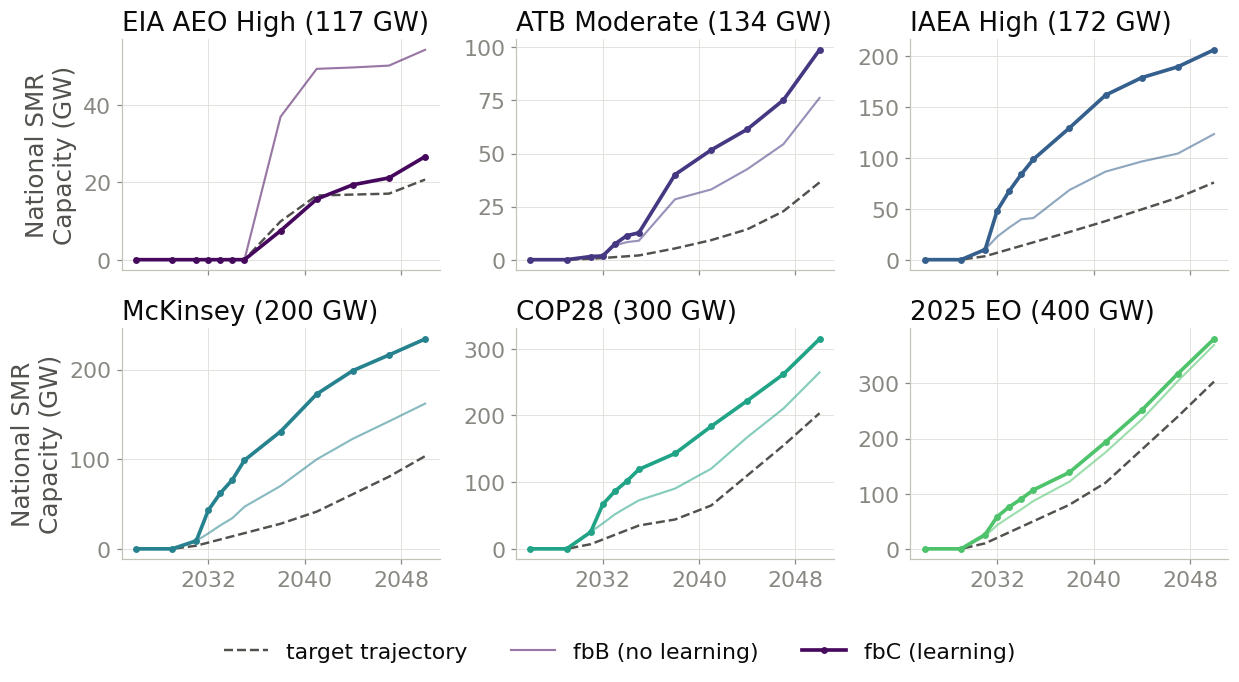

In [9]:
# ---- h03: fbC vs fbB vs trajectory, 2x3 panels -------------------------------------------
def cap_traj_panels(arm_cases, fname, overlay_b=False):
    # type authored for the composed SF11 canvas (see CW_SF11)
    with plt.rc_context(ps.font_rc(CW_SF11)):
        fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.2), sharex=True)
        for ax, w in zip(axes.ravel(), SCHEDULES):
            tr = TRAJ[w]
            yrs = [t for t in YEARS_RUN if t >= 2026]
            tr_y = [tr.get(t, 0.0) / 1000 for t in yrs]
            ax.plot(yrs, tr_y, color=MUTED, ls="--", lw=1.6, label="target trajectory")
            if overlay_b:
                cb = f"fbB_{w}_p50"
                ax.plot(yrs, [SMR_CAP[cb].get(t, 0.0) / 1000 for t in yrs],
                        color=SCHED_C[w], lw=1.4, alpha=0.55, label="fbB (no learning)")
            c = [x for x in arm_cases if META[x]["world"] == w][0]
            lab = "fbC (learning)" if overlay_b else "fbB (no learning)"
            ax.plot(yrs, [SMR_CAP[c].get(t, 0.0) / 1000 for t in yrs],
                    color=SCHED_C[w], lw=2.4, marker="o", ms=3.5, label=lab)
            ax.set_title(SCHED_LABEL[w])
            ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=4, integer=True))
            if w in ("eia", "mck"):
                # wrapped: at the SF11 size the one-line label is longer than the panel is tall
                ax.set_ylabel("National SMR\nCapacity (GW)")
        h, l = axes[0, 0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=3, fontsize=F_SF11["legend"],
                   bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.08, 1, 1))
        ps.savefig(fig, EXP_A / fname)
        plt.show()

cap_traj_panels(ARM_CASES["fbC"], "h03_fbC_trajectory_panels.png", overlay_b=True)

saved -> analysis\results\exports\09\itcfb\h04_delivery_summary.png


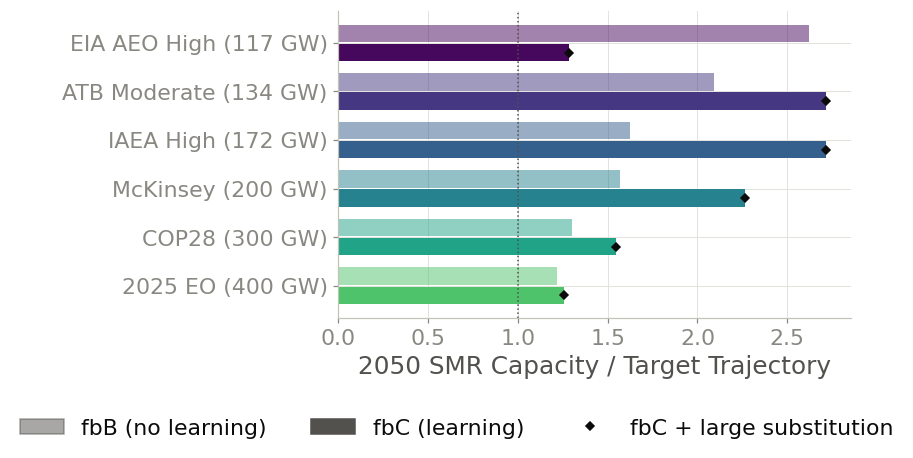

In [10]:
# ---- h04: 2050 delivery summary ------------------------------------------------------------
with plt.rc_context(ps.font_rc(CW_SF11)):
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    y = np.arange(len(SCHEDULES))[::-1]
    fb = [float(SMR_CAP[f"fbB_{w}_p50"].get(2050, 0.0)) / float(TRAJ[w].get(2050))
          for w in SCHEDULES]
    fc = q04.set_index("world")["delivered_frac_2050"].reindex(SCHEDULES).to_numpy()
    fcs = q04.set_index("world")["delivered_frac_2050_substadj"].reindex(SCHEDULES).to_numpy()
    ax.barh(y + 0.2, fb, height=0.36, color=[SCHED_C[w] for w in SCHEDULES], alpha=0.5,
            label="fbB (no learning)")
    ax.barh(y - 0.2, fc, height=0.36, color=[SCHED_C[w] for w in SCHEDULES],
            label="fbC (learning)")
    for yi_, s, f_ in zip(y, fcs, fc):
        ax.plot([s], [yi_ - 0.2], marker="D", ms=4, color=INK, ls="")
    ax.axvline(1.0, color=MUTED, lw=1.0, ls=":")
    ax.set_yticks(y)
    ax.set_yticklabels([SCHED_LABEL[w] for w in SCHEDULES])
    ax.set_xlabel("2050 SMR Capacity / Target Trajectory")
    handles = [plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=0.5),
               plt.Rectangle((0, 0), 1, 1, color=MUTED),
               Line2D([], [], marker="D", ms=4, color=INK, ls="")]
    # below the axes, three across (inside the axes it would cover the IAEA High and McKinsey bars)
    fig.legend(handles, ["fbB (no learning)", "fbC (learning)",
                         "fbC + large substitution"], ncol=3,
               fontsize=F_SF11["legend"], loc="lower center",
               bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.10, 1, 1))
    ps.savefig(fig, EXP_A / "h04_delivery_summary.png")
    plt.show()

## A4. fbK: the engine calibration

The fbK runs keep the mandate and switch learning on without a credit. The learning engine's
in-run cost path must then reproduce the drawn P50 cost path, so that an fbC miss could be
attributed to the economics rather than to an engine error. 06a runs the test (phase C, with the
engine's lagged-experience timing); `q05` adds the 2022 $/kW columns that match the plant input
files. The SMR channel from 2031 is the gate; the large channel is context.

In [11]:
q05 = CAL.copy()
q05["drawn_2022_kW"] = q05["drawn_2004_MW"] / (1000 * D2022)
q05["inrun_2022_kW"] = q05["inrun_2004_MW"] / (1000 * D2022)
q05.to_csv(EXP_A / "q05_fbK_calibration.csv", index=False)
print(q05.groupby(["case", "i"])["rel_err"].max().map("{:.2e}".format))

case         i          
fbK_eia_p50  nuclear        1.05e-03
             nuclear-smr    1.88e-01
fbK_eo_p50   nuclear        1.87e-02
             nuclear-smr    3.07e-02
Name: rel_err, dtype: object


## A5. The rate-deployment curve

The three fbR runs anchor a demand curve at flat monetized rates 0, 0.27 and 0.45 (statutory 0,
30 and 50%), credited to both nuclear technologies in the `eia` world. Each fed world adds one
point for fbB and one for fbC: its mean monetized schedule rate against its 2050 SMR capacity.
The schedule rates vary by year and credit SMRs only, while the anchors are flat and credit both
technologies, so the anchors bound the curve; they do not interpolate it. `q06` is Supplementary
Table 3b; `h06` is Supplementary Fig. 12b, drawn on the monetized basis.

The flat anchors show the cliff that Section B maps: a flat 30% credit builds no SMR at all, and a
flat 50% credit builds 9.8 GW, against 27 to 381 GW at the schedule rates. The large-reactor
fleet stays at 94.11 GW in every run.

In [12]:
RATES = {w: {t: f * (1 - PEN) for t, f in FILE_FB[w].items()} for w in SCHEDULES}   # monetized
rows = []
for c in ARM_CASES["fbR"]:
    m = {"fbR_none": 0.0, "fbR_itc30": 0.27, "fbR_itc50": 0.45}[c]
    rows.append(dict(kind="flat-anchor", case=c, world="eia", m_monetized=m,
                     smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                     large_2050_GW=round(float(LG_CAP[c].get(2050, 0.0)) / 1000, 2),
                     nuclear_2050_GW=round((float(SMR_CAP[c].get(2050, 0.0))
                                            + float(LG_CAP[c].get(2050, 0.0))) / 1000, 2)))
for arm in ["fbB", "fbC"]:
    for w in SCHEDULES:
        c = f"{arm}_{w}_p50"
        rows.append(dict(kind=f"schedule-{arm}", case=c, world=w,
                         m_monetized=round(float(np.mean(list(RATES[w].values()))), 3),
                         smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                         large_2050_GW=round(float(LG_CAP[c].get(2050, 0.0)) / 1000, 2),
                         nuclear_2050_GW=round((float(SMR_CAP[c].get(2050, 0.0))
                                                + float(LG_CAP[c].get(2050, 0.0))) / 1000, 2)))
q06 = pd.DataFrame(rows)
q06.to_csv(EXP_A / "q06_rate_deployment.csv", index=False)
print(q06.to_string(index=False))

        kind          case world  m_monetized  smr_2050_GW  large_2050_GW  nuclear_2050_GW
 flat-anchor      fbR_none   eia        0.000         0.00          94.11            94.11
 flat-anchor     fbR_itc30   eia        0.270         0.00          94.11            94.11
 flat-anchor     fbR_itc50   eia        0.450         9.79          94.11           103.89
schedule-fbB   fbB_eia_p50   eia        0.543        54.22          94.11           148.33
schedule-fbB    fbB_aj_p50    aj        0.569        76.19          94.11           170.29
schedule-fbB  fbB_iaea_p50  iaea        0.648       123.16          94.11           217.27
schedule-fbB   fbB_mck_p50   mck        0.624       161.98          94.11           256.09
schedule-fbB fbB_cop28_p50 cop28        0.671       264.61          94.11           358.72
schedule-fbB    fbB_eo_p50    eo        0.622       369.83          94.11           463.94
schedule-fbC   fbC_eia_p50   eia        0.543        26.63          94.11           120.74

saved -> analysis\results\exports\09\itcfb\h06_deployment_vs_rate.png


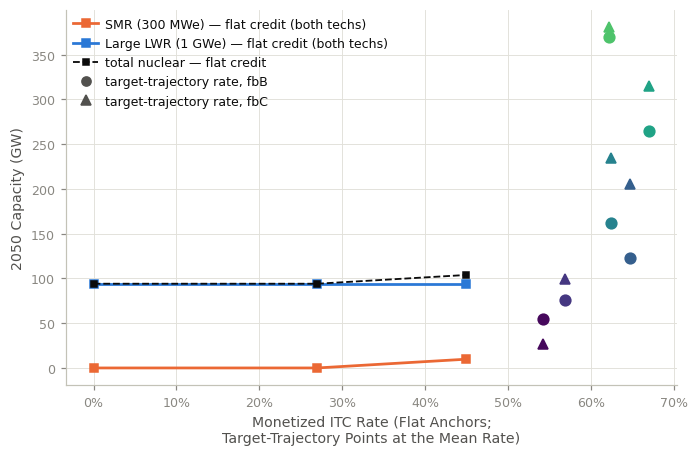

In [13]:
# ---- h06: deployment vs rate, monetized basis ---------------------------------------------
# type authored for the composed SF12 canvas; the figure size matches its SF12 twin j06
with plt.rc_context(ps.font_rc(CW_SF12)):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    anch = q06[q06["kind"] == "flat-anchor"].sort_values("m_monetized")
    for key, col_name in [("smr", "smr_2050_GW"), ("large", "large_2050_GW")]:
        ax.plot(anch["m_monetized"], anch[col_name], color=COL[key], lw=1.8, marker="s",
                ms=5, label=f"{ps.TECH_LABEL[key]} — flat credit (both techs)")
    ax.plot(anch["m_monetized"], anch["nuclear_2050_GW"], color=INK, lw=1.2, ls="--",
            marker="s", ms=4, label="total nuclear — flat credit")
    for arm, mk in [("fbB", "o"), ("fbC", "^")]:
        sub = q06[q06["kind"] == f"schedule-{arm}"]
        for r in sub.itertuples():
            ax.plot(r.m_monetized, r.smr_2050_GW, marker=mk, ms=7, ls="",
                    color=SCHED_C[r.world])
    extra = [Line2D([], [], marker="o", ls="", color=MUTED,
                    label="target-trajectory rate, fbB"),
             Line2D([], [], marker="^", ls="", color=MUTED,
                    label="target-trajectory rate, fbC")]
    h_, l_ = ax.get_legend_handles_labels()
    ax.legend(handles=h_ + extra, fontsize=F_SF12["legend"], loc="upper left",
              handletextpad=0.5, borderaxespad=0.2)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))   # a credit rate in percent
    ax.set_xlabel("Monetized ITC Rate (Flat Anchors;\nTarget-Trajectory Points at the Mean Rate)")
    ax.set_ylabel("2050 Capacity (GW)")
    fig.tight_layout()
    ps.savefig(fig, EXP_A / "h06_deployment_vs_rate.png")
    plt.show()

## A6. Large-reactor substitution (context)

A credit does not force the SMR: under the design-neutral flat credit (fbR) and even under the
SMR-only schedule credit (fbB, fbC), ReEDS could choose large reactors instead. `q07` reports the
2050 large-reactor capacity of every run against its world's base mandate run. No run builds new
large reactors after 2030, so the substitution adjustment of `q04` changes nothing.

In [14]:
q07 = q00[["case", "arm", "world", "smr_2050_GW", "large_2050_GW",
           "new_large_post2030_GW"]].copy()
base_lg = {w: round(float(LG_CAP[BASE_OF_WORLD[w]].get(2050, 0.0)) / 1000, 2)
           for w in SCHEDULES}
q07["base_large_2050_GW"] = q07["world"].map(base_lg)
q07["large_above_base_GW"] = (q07["large_2050_GW"] - q07["base_large_2050_GW"]).round(2)
q07.to_csv(EXP_A / "q07_large_substitution.csv", index=False)
print(q07.to_string(index=False))

         case arm world  smr_2050_GW  large_2050_GW  new_large_post2030_GW  base_large_2050_GW  large_above_base_GW
  fbA_eia_p50 fbA   eia        54.22          94.11                    0.0               94.11                  0.0
   fbA_eo_p50 fbA    eo       369.83          94.11                    0.0               94.11                  0.0
  fbB_eia_p50 fbB   eia        54.22          94.11                    0.0               94.11                  0.0
   fbB_aj_p50 fbB    aj        76.19          94.11                    0.0               94.11                  0.0
 fbB_iaea_p50 fbB  iaea       123.16          94.11                    0.0               94.11                  0.0
  fbB_mck_p50 fbB   mck       161.98          94.11                    0.0               94.11                  0.0
fbB_cop28_p50 fbB cop28       264.61          94.11                    0.0               94.11                  0.0
   fbB_eo_p50 fbB    eo       369.83          94.11                    0

# Section B. The minus probe (`itcfbm`, 24 runs)

Section A shows that the headline rate delivers the target. The minus probe asks how much of the
headline rate is necessary. Each run feeds the rate `i_model_headline - d` for a decrement `d` of
1, 5, 10 or 15 rate points, measured from the headline in the same units as every rate the paper
quotes. The *rung* names are m01, m05, m10 and m15; the main-set run at the headline plus the bump
is rung p01. One arm freezes learning (fbBm, the minus sibling of fbB) and one uses
draw-calibrated endogenous learning (fbCm, the sibling of fbC). No minus run has a mandate.

**Worlds.** The probe uses `aj`, `mck` and `eo`: three trajectories that span 2031 to 2050 and
that all reproduce the target at the headline rate, so the decrements isolate the rate effect.
`eia` is left out because fbC_eia is already partial at the full headline rate (a delayed start
under learning), which would confound the rate effect with the start-timing effect.

**Claim separation (pre-registered).** The runs test *delivery minimality* only: the lowest
uniform rate at which the model still builds the target. They do not test the shadow prices. The
shadow price is marginal-breakeven by linear-programming duality, and the in-model reduced-cost
check already verifies it. A below-headline rung that still delivers therefore shows that the
uniform headline (a max-region rate) was not delivery-minimal. It does not show that the shadow
prices were wrong.

## B0. Quality gate and the rate ladder table

The gate reads both 06a registries. The fed rates come from the audited echoes of Section 2.
`r00` is the inventory of the 30 ladder cells (2 arms x 3 worlds x 5 rungs) and the three flat
anchors, with the mean file rate and the mean monetized rate of each cell.

In [15]:
summ_m = pd.read_csv(CHECKSM / "checks_summary.csv")
for name, s in [("itcfbm_checks", summ_m), ("itcfb_checks", summary)]:
    hard = s[(s["status"] == "FAIL") & s["phase"].isin(["A", "B", "D"])]
    assert not len(hard), f"mechanical-integrity FAILs in {name}:\n{hard}"
    c_fails = s[(s["status"] == "FAIL") & (s["phase"] == "C")]
    if len(c_fails):
        print(f"{name}: pre-registered phase-C FAILs (findings, not blockers):")
        print(c_fails[["check", "detail"]].to_string(index=False))
    else:
        print(f"{name}: no phase-C failures")

WORLDS = ["aj", "mck", "eo"]                        # ordered by 2050 ambition
LADDER = ["m15", "m10", "m05", "m01", "p01"]        # deep to shallow; p01 = main set
CUT = {"m15": 0.15, "m10": 0.10, "m05": 0.05, "m01": 0.01, "p01": -0.01}
assert all(w in ps.SCHED_ORDER for w in WORLDS)

def parse_case_m(c):
    tok, world = c.split("_")[0], c.split("_")[1]
    return tok[:-2], "m" + tok[-2:], world          # (arm, rung, world)

META_M = {c: dict(zip(("arm", "rung", "world"), parse_case_m(c))) for c in CASES_M}

def run_of(arm, rung, world):
    # Map an (arm, rung, world) ladder cell to its run; p01 is the main-set sibling (fbBm -> fbB).
    if rung == "p01":
        return f"{arm[:-1]}_{world}_p50"
    return f"{arm}{rung[1:]}_{world}_p50"

SIBLING_CASES = sorted({run_of(a, "p01", w) for a in ["fbBm", "fbCm"] for w in WORLDS})
FLAT_CASES = ["fbR_none", "fbR_itc30", "fbR_itc50"]
ALL_RUNS = CASES_M + SIBLING_CASES + FLAT_CASES

GAPS_M = pd.read_csv(CHECKSM / "trajectory_gaps.csv")
OUT_M = pd.read_csv(CHECKSM / "delivery_outcomes.csv")
PARITY = pd.read_csv(paths.DATA / "reeds_inputs" / "budget_parity_context.csv")

# fed rates: the audited file echoes of Section 2
FED = {}                                            # (world, rung) -> {t: itc_frac}
for w in WORLDS:
    for g in DECS:
        sub = ECHO_M[(ECHO_M["world"] == w) & (ECHO_M["rung"] == g)]
        FED[(w, g)] = dict(zip(sub["t"], sub["itc_frac_file"]))
    sub = ECHO_FB[ECHO_FB["world"] == w]
    FED[(w, "p01")] = dict(zip(sub["t"], sub["itc_frac_file"]))
M_MEAN = {k: round(float(np.mean(list(v.values()))) * (1 - PEN), 3) for k, v in FED.items()}
FLAT_M = {"fbR_none": 0.0, "fbR_itc30": 0.27, "fbR_itc50": 0.45}

# consistency: the 06a outcome table and the extracts describe the same runs
cap_x = float(SMR_CAP["fbCm15_aj_p50"].get(2050, 0.0))
cap_qa = OUT_M[OUT_M["case"] == "fbCm15_aj_p50"]["smr_2050_MW"].iloc[0]
assert abs(cap_x - cap_qa) < 1.0
print(f"consistent: fbCm15_aj_p50 2050 SMR capacity {cap_x:,.0f} MW matches the 06a table")

rows = []
for arm in ["fbBm", "fbCm"]:
    for w in WORLDS:
        for g in LADDER:
            c = run_of(arm, g, w)
            rows.append(dict(case=c, set="itcfb" if g == "p01" else "itcfbm",
                             arm=arm, rung=g, world=w,
                             fed_mean=round(float(np.mean(list(FED[(w, g)].values()))), 3),
                             m_monetized=M_MEAN[(w, g)],
                             smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                             traj_2050_GW=round(float(TRAJ[w].get(2050)) / 1000, 2),
                             new_large_post2030_GW=round(float(LG_NEW[c].sum()) / 1000, 2)))
for c in FLAT_CASES:
    rows.append(dict(case=c, set="itcfb", arm="fbR", rung="flat", world="",
                     fed_mean=round(FLAT_M[c] / (1 - PEN), 3) if FLAT_M[c] else 0.0,
                     m_monetized=FLAT_M[c],
                     smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                     traj_2050_GW=np.nan,
                     new_large_post2030_GW=round(float(LG_NEW[c].sum()) / 1000, 2)))
r00 = pd.DataFrame(rows)
r00.to_csv(EXP_B / "r00_run_inventory.csv", index=False)
print(r00.to_string(index=False))

itcfbm_checks: no phase-C failures
itcfb_checks: no phase-C failures
consistent: fbCm15_aj_p50 2050 SMR capacity 141 MW matches the 06a table
          case    set  arm rung world  fed_mean  m_monetized  smr_2050_GW  traj_2050_GW  new_large_post2030_GW
 fbBm15_aj_p50 itcfbm fbBm  m15    aj     0.472        0.425        12.96          36.4                    0.0
 fbBm10_aj_p50 itcfbm fbBm  m10    aj     0.522        0.470        21.96          36.4                    0.0
 fbBm05_aj_p50 itcfbm fbBm  m05    aj     0.572        0.515        33.39          36.4                    0.0
 fbBm01_aj_p50 itcfbm fbBm  m01    aj     0.612        0.551        57.00          36.4                    0.0
    fbB_aj_p50  itcfb fbBm  p01    aj     0.632        0.569        76.19          36.4                    0.0
fbBm15_mck_p50 itcfbm fbBm  m15   mck     0.533        0.480        27.71         103.4                    0.0
fbBm10_mck_p50 itcfbm fbBm  m10   mck     0.583        0.525        48.00        

## B1. Where the rungs sit: the monetized-parity rate

`r01` lists the fed rate of every (world, rung, rate year) next to the *monetized-parity rate*
`i_par` of the design record `budget_parity_context.csv`. The parity rate is the uniform rate at
which the total monetized credit across all builds equals the sum of the shadow-price-valued gaps
of the base run: `i_par = i_head / ov_t`, where `ov_t` is the overshoot of the max-region uniform
rate over the build-weighted need (the t13 convention of notebook 07). The cut `cut_par =
i_head - i_par` is how far the uniform rate could fall before the aggregate credit stops covering
the aggregate gap. The fiscal companion `i_fiscal` also strips the 10% haircut; it is budget
context only, because the haircut goes to tax-equity investors and never reaches a builder.

The ladder was placed on this record before the runs: m01 and m05 sample inside the parity band,
m10 sits below the parity rate in every rate year, and m15 is the deep probe. The cell first
asserts that the record's `i_head` still equals the current t09 headline rate.

In [16]:
for r in PARITY.itertuples():
    assert round(HEAD[r.world][int(r.t)], 3) == r.i_head, \
        f"parity record i_head differs from t09 for {r.world} {r.t}: the ladder design is stale"
assert {(r.world, int(r.t)) for r in PARITY.itertuples()} == \
    {(w, t) for w in WORLDS for t in HEAD[w]}, "the parity record covers every rate year"

rows = []
par = PARITY.set_index(["world", "t"])
for w in WORLDS:
    for g in LADDER:
        for t, f in sorted(FED[(w, g)].items()):
            p = par.loc[(w, t)]
            rows.append(dict(world=w, rung=g, t=t, itc_frac=f,
                             m_monetized=round(f * (1 - PEN), 4),
                             i_head=p["i_head"], i_par=p["i_par"],
                             cut_par=p["cut_par"], i_fiscal=p["i_fiscal"],
                             below_parity=bool(f < p["i_par"])))
r01 = pd.DataFrame(rows)
r01.to_csv(EXP_B / "r01_rate_ladder.csv", index=False)
below = r01.groupby(["world", "rung"])["below_parity"].mean().unstack()
print("share of rate years below the parity rate:")
print(below.reindex(columns=LADDER).round(2).to_string())

share of rate years below the parity rate:
rung   m15  m10  m05  m01  p01
world                         
aj     1.0  1.0  0.4  0.3  0.0
eo     1.0  1.0  0.6  0.0  0.0
mck    1.0  1.0  0.5  0.0  0.0


## B2. Delivery down the ladder

`r02` merges the per-year trajectory gaps of the 24 minus runs (06a `itcfbm_checks`) with those of
the six main-set siblings (06a `itcfb_checks`, renamed to the ladder arms fbBm and fbCm, rung p01).
The gaps use national cumulative SMR capacity, because the mandate counts all vintages. The
column `cut` is the rate cut below the headline (negative for p01, which sits 0.01 above it).

In [17]:
sib_gaps = GAPS[GAPS["arm"].isin(["fbB", "fbC"]) & GAPS["world"].isin(WORLDS)].copy()
sib_gaps["rung"] = "p01"
sib_gaps["arm"] = sib_gaps["arm"] + "m"             # ladder arm naming: fbBm / fbCm
r02 = pd.concat([GAPS_M, sib_gaps[GAPS_M.columns]], ignore_index=True)
r02["cut"] = r02["rung"].map(CUT)
r02.to_csv(EXP_B / "r02_delivery_gaps.csv", index=False)
print(r02.groupby(["arm", "rung"])["gap_pct"].agg(["min", "max"]).round(1))

            min    max
arm  rung             
fbBm m01  -15.1  204.0
     m05  -54.0   27.8
     m10  -85.0  -25.2
     m15  -93.4  -44.7
     p01   21.9  457.7
fbCm m01  -15.1  208.3
     m05  -68.5   17.7
     m10  -98.4  -25.2
     m15  -99.6  -64.7
     p01   25.5  655.9


## B3. The delivery-minimal rate

Each ladder cell gets a tier and an *outcome*. For the minus runs both come from 06a
(`delivery_outcomes.csv`): *full-delivery* (tier exact or reproduces), *partial*,
*delayed-start-recover* (a late start that recovers) or *under-delivery*. For the p01 siblings the
tier comes from the same `tier_of` rule on the gap rows.

**Verdict rule (pre-registered).** For each (arm, world) ladder, the *deepest delivering rung* is
the deepest rung with full delivery, and the *shallowest failing rung* is the next rung below it.
The *delivery-minimal uniform rate* lies between the two rungs' rates. `r03` (Supplementary
Table 3c) holds the bracket and the delivered 2050 fraction at every rung.

Result: in all six ladders delivery survives one point below the headline and fails five points
below, so the delivery-minimal uniform rate lies in (headline - 0.05, headline - 0.01].

In [18]:
cell_rows = []
for arm in ["fbBm", "fbCm"]:
    for w in WORLDS:
        for g in LADDER:
            c = run_of(arm, g, w)
            if g == "p01":
                t_ = tier_of(r02[r02["case"] == c])
                outcome = "full-delivery" if t_ in ("exact", "reproduces") else t_
            else:
                row = OUT_M[OUT_M["case"] == c].iloc[0]
                t_, outcome = row["tier"], row["outcome"]
            frac = float(SMR_CAP[c].get(2050, 0.0)) / float(TRAJ[w].get(2050))
            cell_rows.append(dict(arm=arm, world=w, rung=g, case=c, cut=CUT[g],
                                  fed_mean=round(float(np.mean(list(FED[(w, g)].values()))), 3),
                                  m_monetized=M_MEAN[(w, g)], tier=t_, outcome=outcome,
                                  delivered_frac_2050=round(frac, 4)))
cells = pd.DataFrame(cell_rows)
print(cells.pivot_table(index=["arm", "world"], columns="rung",
                        values="delivered_frac_2050").reindex(columns=LADDER)
      .round(3).to_string())

# ---- r03: the delivery-minimality verdicts ---------------------------------------------
rows = []
for arm in ["fbBm", "fbCm"]:
    for w in WORLDS:
        sub = cells[(cells["arm"] == arm) & (cells["world"] == w)] \
            .set_index("rung").reindex(LADDER)
        deliver = sub[sub["outcome"] == "full-delivery"]
        deepest = deliver.iloc[0].name if len(deliver) else None
        below_ = [g for g in LADDER[:LADDER.index(deepest)]] if deepest else LADDER
        shallowest_fail = below_[-1] if below_ else None
        rows.append(dict(
            arm=arm, world=w,
            deepest_delivering_rung=deepest,
            cut_points=CUT.get(deepest) if deepest else None,
            cut_monetized=round(0.9 * CUT[deepest], 3) if deepest else None,
            shallowest_failing_rung=shallowest_fail,
            failing_cut_points=CUT.get(shallowest_fail) if shallowest_fail else None,
            failing_outcome=(sub.loc[shallowest_fail, "outcome"]
                             if shallowest_fail else None),
            delivered_frac_at_fail=(sub.loc[shallowest_fail, "delivered_frac_2050"]
                                    if shallowest_fail else None),
            outcomes_down_ladder=" > ".join(sub["outcome"].loc[LADDER[::-1]]),
        ))
r03 = pd.DataFrame(rows)
r03 = r03.merge(cells[["arm", "world", "rung", "delivered_frac_2050"]]
                .pivot_table(index=["arm", "world"], columns="rung",
                             values="delivered_frac_2050")
                .reindex(columns=LADDER)
                .rename(columns=lambda g: f"frac_{g}").reset_index(),
                on=["arm", "world"])
r03.to_csv(EXP_B / "r03_minimality_verdicts.csv", index=False)
print(r03.to_string(index=False))

d_ok = r03["deepest_delivering_rung"].value_counts().to_dict()
print(f"\nREADING: deepest delivering rung by ladder: {d_ok}; shallowest failing rung: "
      f"{r03['shallowest_failing_rung'].value_counts().to_dict()}. A rung below the headline "
      "that delivers shows the uniform headline was not delivery-minimal, not that the "
      "shadow prices were wrong.")

rung          m15    m10    m05    m01    p01
arm  world                                   
fbBm aj     0.356  0.603  0.917  1.566  2.093
     eo     0.553  0.730  0.954  1.148  1.219
     mck    0.268  0.464  0.852  1.346  1.567
fbCm aj     0.004  0.201  0.706  1.397  2.715
     eo     0.309  0.534  0.888  1.171  1.255
     mck    0.009  0.016  0.328  1.851  2.264
 arm world deepest_delivering_rung  cut_points  cut_monetized shallowest_failing_rung  failing_cut_points       failing_outcome  delivered_frac_at_fail                                                                    outcomes_down_ladder  frac_m15  frac_m10  frac_m05  frac_m01  frac_p01
fbBm    aj                     m01        0.01          0.009                     m05                0.05               partial                  0.9173               full-delivery > full-delivery > partial > under-delivery > under-delivery    0.3562    0.6032    0.9173    1.5661    2.0931
fbBm   mck                     m01        0.01      

## B4. The cliff

`r04` (Supplementary Table 3d) extends the `q06` table with the 24 minus rungs: the flat anchors,
the main-set schedule points and every ladder cell, each with its mean monetized rate and its 2050
capacities.

`j06` (Supplementary Fig. 12a) plots new-nuclear 2050 capacity against the **statutory** rate on
the model convention (monetized rate / 0.9), so the flat anchors sit at 0, 30 and 50% and the
current 48E credit range (30 to 50%) can be shaded. New nuclear equals SMR capacity exactly,
because the large-reactor fleet is the same in every run; the cell asserts this. Solid curves are
the fbCm ladders (endogenous learning) with their p01 points; faint dashed curves are the fbBm
ladders (learning frozen); the three headline-only worlds appear as single points.

**The cliff.** The response to the rate is a cliff, not a slope. The whole current-law 48E range
sits in the flat tail: zero SMR at a flat 30% and 9.8 GW at a flat 50%. A few points below each
world's headline rate, delivery collapses.

In [19]:
new_rows = []
for r in cells.itertuples():
    if r.rung == "p01":
        continue     # already in q06 as schedule-fbB / schedule-fbC
    new_rows.append(dict(kind=f"schedule-{r.arm}", case=r.case, world=r.world,
                         m_monetized=r.m_monetized,
                         smr_2050_GW=round(float(SMR_CAP[r.case].get(2050, 0.0)) / 1000, 2),
                         large_2050_GW=round(float(LG_CAP[r.case].get(2050, 0.0)) / 1000, 2),
                         nuclear_2050_GW=round((float(SMR_CAP[r.case].get(2050, 0.0))
                                                + float(LG_CAP[r.case].get(2050, 0.0)))
                                               / 1000, 2),
                         set="itcfbm", rung=r.rung))
q06x = pd.read_csv(EXP_A / "q06_rate_deployment.csv")
q06x["set"] = "itcfb"
q06x["rung"] = np.where(q06x["kind"] == "flat-anchor", "flat", "p01")
r04 = pd.concat([q06x, pd.DataFrame(new_rows)], ignore_index=True)
r04.to_csv(EXP_B / "r04_rate_deployment.csv", index=False)
assert len(r04) == len(q06x) + 24, "r04 = the 15 q06 rows plus the 24 minus rungs"
print(r04.to_string(index=False))

         kind           case world  m_monetized  smr_2050_GW  large_2050_GW  nuclear_2050_GW    set rung
  flat-anchor       fbR_none   eia        0.000         0.00          94.11            94.11  itcfb flat
  flat-anchor      fbR_itc30   eia        0.270         0.00          94.11            94.11  itcfb flat
  flat-anchor      fbR_itc50   eia        0.450         9.79          94.11           103.89  itcfb flat
 schedule-fbB    fbB_eia_p50   eia        0.543        54.22          94.11           148.33  itcfb  p01
 schedule-fbB     fbB_aj_p50    aj        0.569        76.19          94.11           170.29  itcfb  p01
 schedule-fbB   fbB_iaea_p50  iaea        0.648       123.16          94.11           217.27  itcfb  p01
 schedule-fbB    fbB_mck_p50   mck        0.624       161.98          94.11           256.09  itcfb  p01
 schedule-fbB  fbB_cop28_p50 cop28        0.671       264.61          94.11           358.72  itcfb  p01
 schedule-fbB     fbB_eo_p50    eo        0.622       3

saved -> analysis\results\exports\09\itcfbm\j06_new_nuclear_cliff.png


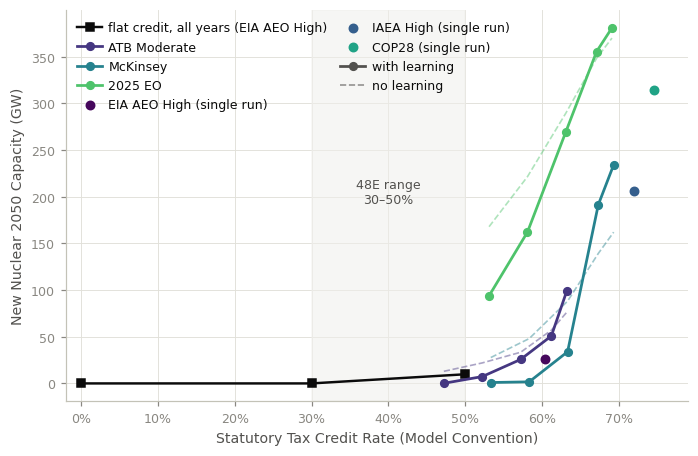

In [20]:
# ---- j06: the cliff, statutory basis, new nuclear only ------------------------------------
j06 = pd.read_csv(EXP_B / "r04_rate_deployment.csv")
assert j06["large_2050_GW"].nunique() == 1, "large-reactor capacity must not move with the credit"
j06["new_GW"] = j06["smr_2050_GW"]                  # so new nuclear = SMR exactly
j06["i_stat"] = j06["m_monetized"] / (1 - PEN)      # statutory rate, model convention
J06_LAB = dict(ps.SCHED_SHORT)                      # paper-facing schedule names

# type authored for the composed SF12 canvas (see CW_SF12)
with plt.rc_context(ps.font_rc(CW_SF12)):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.axvspan(0.30, 0.50, color=ps.NEUTRAL, alpha=0.55, zorder=1)
    ax.text(0.40, 220, "48E range\n30–50%", fontsize=F_SF12["annotation"],
            color=MUTED, ha="center", va="top")

    flat = j06[j06["kind"] == "flat-anchor"].sort_values("i_stat")
    assert [round(v, 2) for v in flat["i_stat"]] == [0.0, 0.30, 0.50]
    ax.plot(flat["i_stat"], flat["new_GW"], marker="s", ms=5, lw=1.6, color=INK,
            zorder=4, label="flat credit, all years (EIA AEO High)")

    for w in WORLDS:                                # the three minus-probe ladder worlds
        fbc = j06[j06["kind"].isin(["schedule-fbCm", "schedule-fbC"])
                  & (j06["world"] == w)].sort_values("i_stat")
        ax.plot(fbc["i_stat"], fbc["new_GW"], marker="o", ms=5, lw=1.8,
                color=SCHED_C[w], zorder=5, label=J06_LAB[w])
        fbb = j06[j06["kind"].isin(["schedule-fbBm", "schedule-fbB"])
                  & (j06["world"] == w)].sort_values("i_stat")
        ax.plot(fbb["i_stat"], fbb["new_GW"], lw=1.1, ls="--", alpha=0.45,
                color=SCHED_C[w], zorder=3)
    for w in ["eia", "iaea", "cop28"]:              # headline-only worlds
        pt = j06[(j06["kind"] == "schedule-fbC") & (j06["world"] == w)]
        ax.scatter(pt["i_stat"], pt["new_GW"], marker="o", s=30, color=SCHED_C[w],
                   zorder=5, label=J06_LAB[w] + " (single run)")
    ax.plot([], [], color=MUTED, lw=1.8, marker="o", ms=5, label="with learning")
    ax.plot([], [], color=MUTED, lw=1.1, ls="--", alpha=0.6, label="no learning")
    ax.set_xlabel("Statutory Tax Credit Rate (Model Convention)")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.set_ylabel("New Nuclear 2050 Capacity (GW)")
    ax.set_xlim(-0.02, 0.79)
    ax.legend(fontsize=F_SF12["legend"], ncol=2, loc="upper left",
              handletextpad=0.5, columnspacing=1.0)
    fig.tight_layout()
    ps.savefig(fig, EXP_B / "j06_new_nuclear_cliff.png")
    plt.show()

## B5. The ignition cushion

The learning arm answers what endogenous learning adds near the delivery boundary. Above the
boundary, learning adds capacity: builds lower the cost, which brings more builds (a *cushion*).
Below the boundary the same feedback runs in reverse: few builds keep the cost high, which keeps
builds few (a *drag*). `r05` gives the cushion, the fbCm minus the fbBm delivered 2050 fraction,
per world and rung, with the first-build year of each run (a test for the delayed-start signature
of fbC_eia).

The cushion is negative at all nine failing cells (m05, m10, m15) and positive at five of the six
delivering cells (m01, p01); `aj` at m01 is the exception. Learning therefore sharpens the cliff
instead of softening it: below the boundary it amplifies the shortfall, above it amplifies
delivery. The bracket of B3 together with this one-sided behaviour is the basis of the
three-point display allowance that the credit-rate figures of notebook 10 apply.

In [21]:
cush_rows = []
for w in WORLDS:
    for g in LADDER:
        fb = cells[(cells["arm"] == "fbBm") & (cells["world"] == w)
                   & (cells["rung"] == g)].iloc[0]
        fc = cells[(cells["arm"] == "fbCm") & (cells["world"] == w)
                   & (cells["rung"] == g)].iloc[0]
        first_b = OUT_M[OUT_M["case"] == fb.case]["first_build_year"].iloc[0] \
            if g != "p01" else 2031
        first_c = OUT_M[OUT_M["case"] == fc.case]["first_build_year"].iloc[0] \
            if g != "p01" else 2031
        cush_rows.append(dict(world=w, rung=g, cut=CUT[g],
                              frac_fbBm=fb.delivered_frac_2050,
                              frac_fbCm=fc.delivered_frac_2050,
                              cushion=round(fc.delivered_frac_2050
                                            - fb.delivered_frac_2050, 4),
                              first_build_fbBm=first_b, first_build_fbCm=first_c,
                              outcome_fbBm=fb.outcome, outcome_fbCm=fc.outcome))
r05 = pd.DataFrame(cush_rows)
r05.to_csv(EXP_B / "r05_ignition_cushion.csv", index=False)
print(r05.to_string(index=False))

world rung   cut  frac_fbBm  frac_fbCm  cushion  first_build_fbBm  first_build_fbCm          outcome_fbBm   outcome_fbCm
   aj  m15  0.15     0.3562     0.0039  -0.3523              2031              2031        under-delivery under-delivery
   aj  m10  0.10     0.6032     0.2009  -0.4023              2031              2031        under-delivery under-delivery
   aj  m05  0.05     0.9173     0.7055  -0.2118              2031              2031               partial under-delivery
   aj  m01  0.01     1.5661     1.3969  -0.1692              2031              2031         full-delivery  full-delivery
   aj  p01 -0.01     2.0931     2.7154   0.6223              2031              2031         full-delivery  full-delivery
  mck  m15  0.15     0.2679     0.0093  -0.2586              2031              2031        under-delivery under-delivery
  mck  m10  0.10     0.4642     0.0164  -0.4478              2031              2031        under-delivery under-delivery
  mck  m05  0.05     0.8522     

## B6. Substitution (context)

`r06` reports the 2050 SMR and large-reactor capacity and the new large builds after 2030 of all
33 runs read in Section B, with each world's base-run large fleet as the baseline. No run builds
new large reactors.

In [22]:
rows = []
for c in ALL_RUNS:
    m = META_M.get(c, {})
    w_ = m.get("world", c.split("_")[1] if c in SIBLING_CASES else "")
    rows.append(dict(case=c,
                     arm=m.get("arm", c.split("_")[0]),
                     rung=m.get("rung", "p01" if c in SIBLING_CASES else "flat"),
                     world=w_,
                     smr_2050_GW=round(float(SMR_CAP[c].get(2050, 0.0)) / 1000, 2),
                     large_2050_GW=round(float(LG_CAP[c].get(2050, 0.0)) / 1000, 2),
                     new_large_post2030_GW=round(float(LG_NEW[c].sum()) / 1000, 2)))
r06 = pd.DataFrame(rows)
base_lg_m = {w: round(float(LG_CAP[BASE_OF_WORLD[w]].get(2050, 0.0)) / 1000, 2)
             for w in WORLDS}
r06["base_large_2050_GW"] = r06["world"].map(base_lg_m)
r06.to_csv(EXP_B / "r06_substitution.csv", index=False)
n_sub = int((r06["new_large_post2030_GW"] > 0).sum())
print(r06.to_string(index=False))
print(f"\nruns with new large builds after 2030: {n_sub}")

          case  arm rung world  smr_2050_GW  large_2050_GW  new_large_post2030_GW  base_large_2050_GW
 fbBm01_aj_p50 fbBm  m01    aj        57.00          94.11                    0.0               94.11
fbBm01_mck_p50 fbBm  m01   mck       139.19          94.11                    0.0               94.11
 fbBm01_eo_p50 fbBm  m01    eo       348.24          94.11                    0.0               94.11
 fbBm05_aj_p50 fbBm  m05    aj        33.39          94.11                    0.0               94.11
fbBm05_mck_p50 fbBm  m05   mck        88.12          94.11                    0.0               94.11
 fbBm05_eo_p50 fbBm  m05    eo       289.52          94.11                    0.0               94.11
 fbBm10_aj_p50 fbBm  m10    aj        21.96          94.11                    0.0               94.11
fbBm10_mck_p50 fbBm  m10   mck        48.00          94.11                    0.0               94.11
 fbBm10_eo_p50 fbBm  m10    eo       221.44          94.11                    0.0 

# Supplementary Figs. 11 and 12

Supplementary Fig. 11 stacks `h04` (a, the 2050 delivery summary) over `h03` (b, the delivered
paths). Supplementary Fig. 12 stacks `j06` (a, the cliff on the statutory basis) over `h06` (b,
the demand curve on the monetized basis). The composer pastes the panels at native pixel size,
centres the rows, and stamps the letters at the size the printed type specification gives for
each composite width.

composed -> analysis\results\figures\si\SF11_closed_loop_delivery.png  (3477x3255 px)


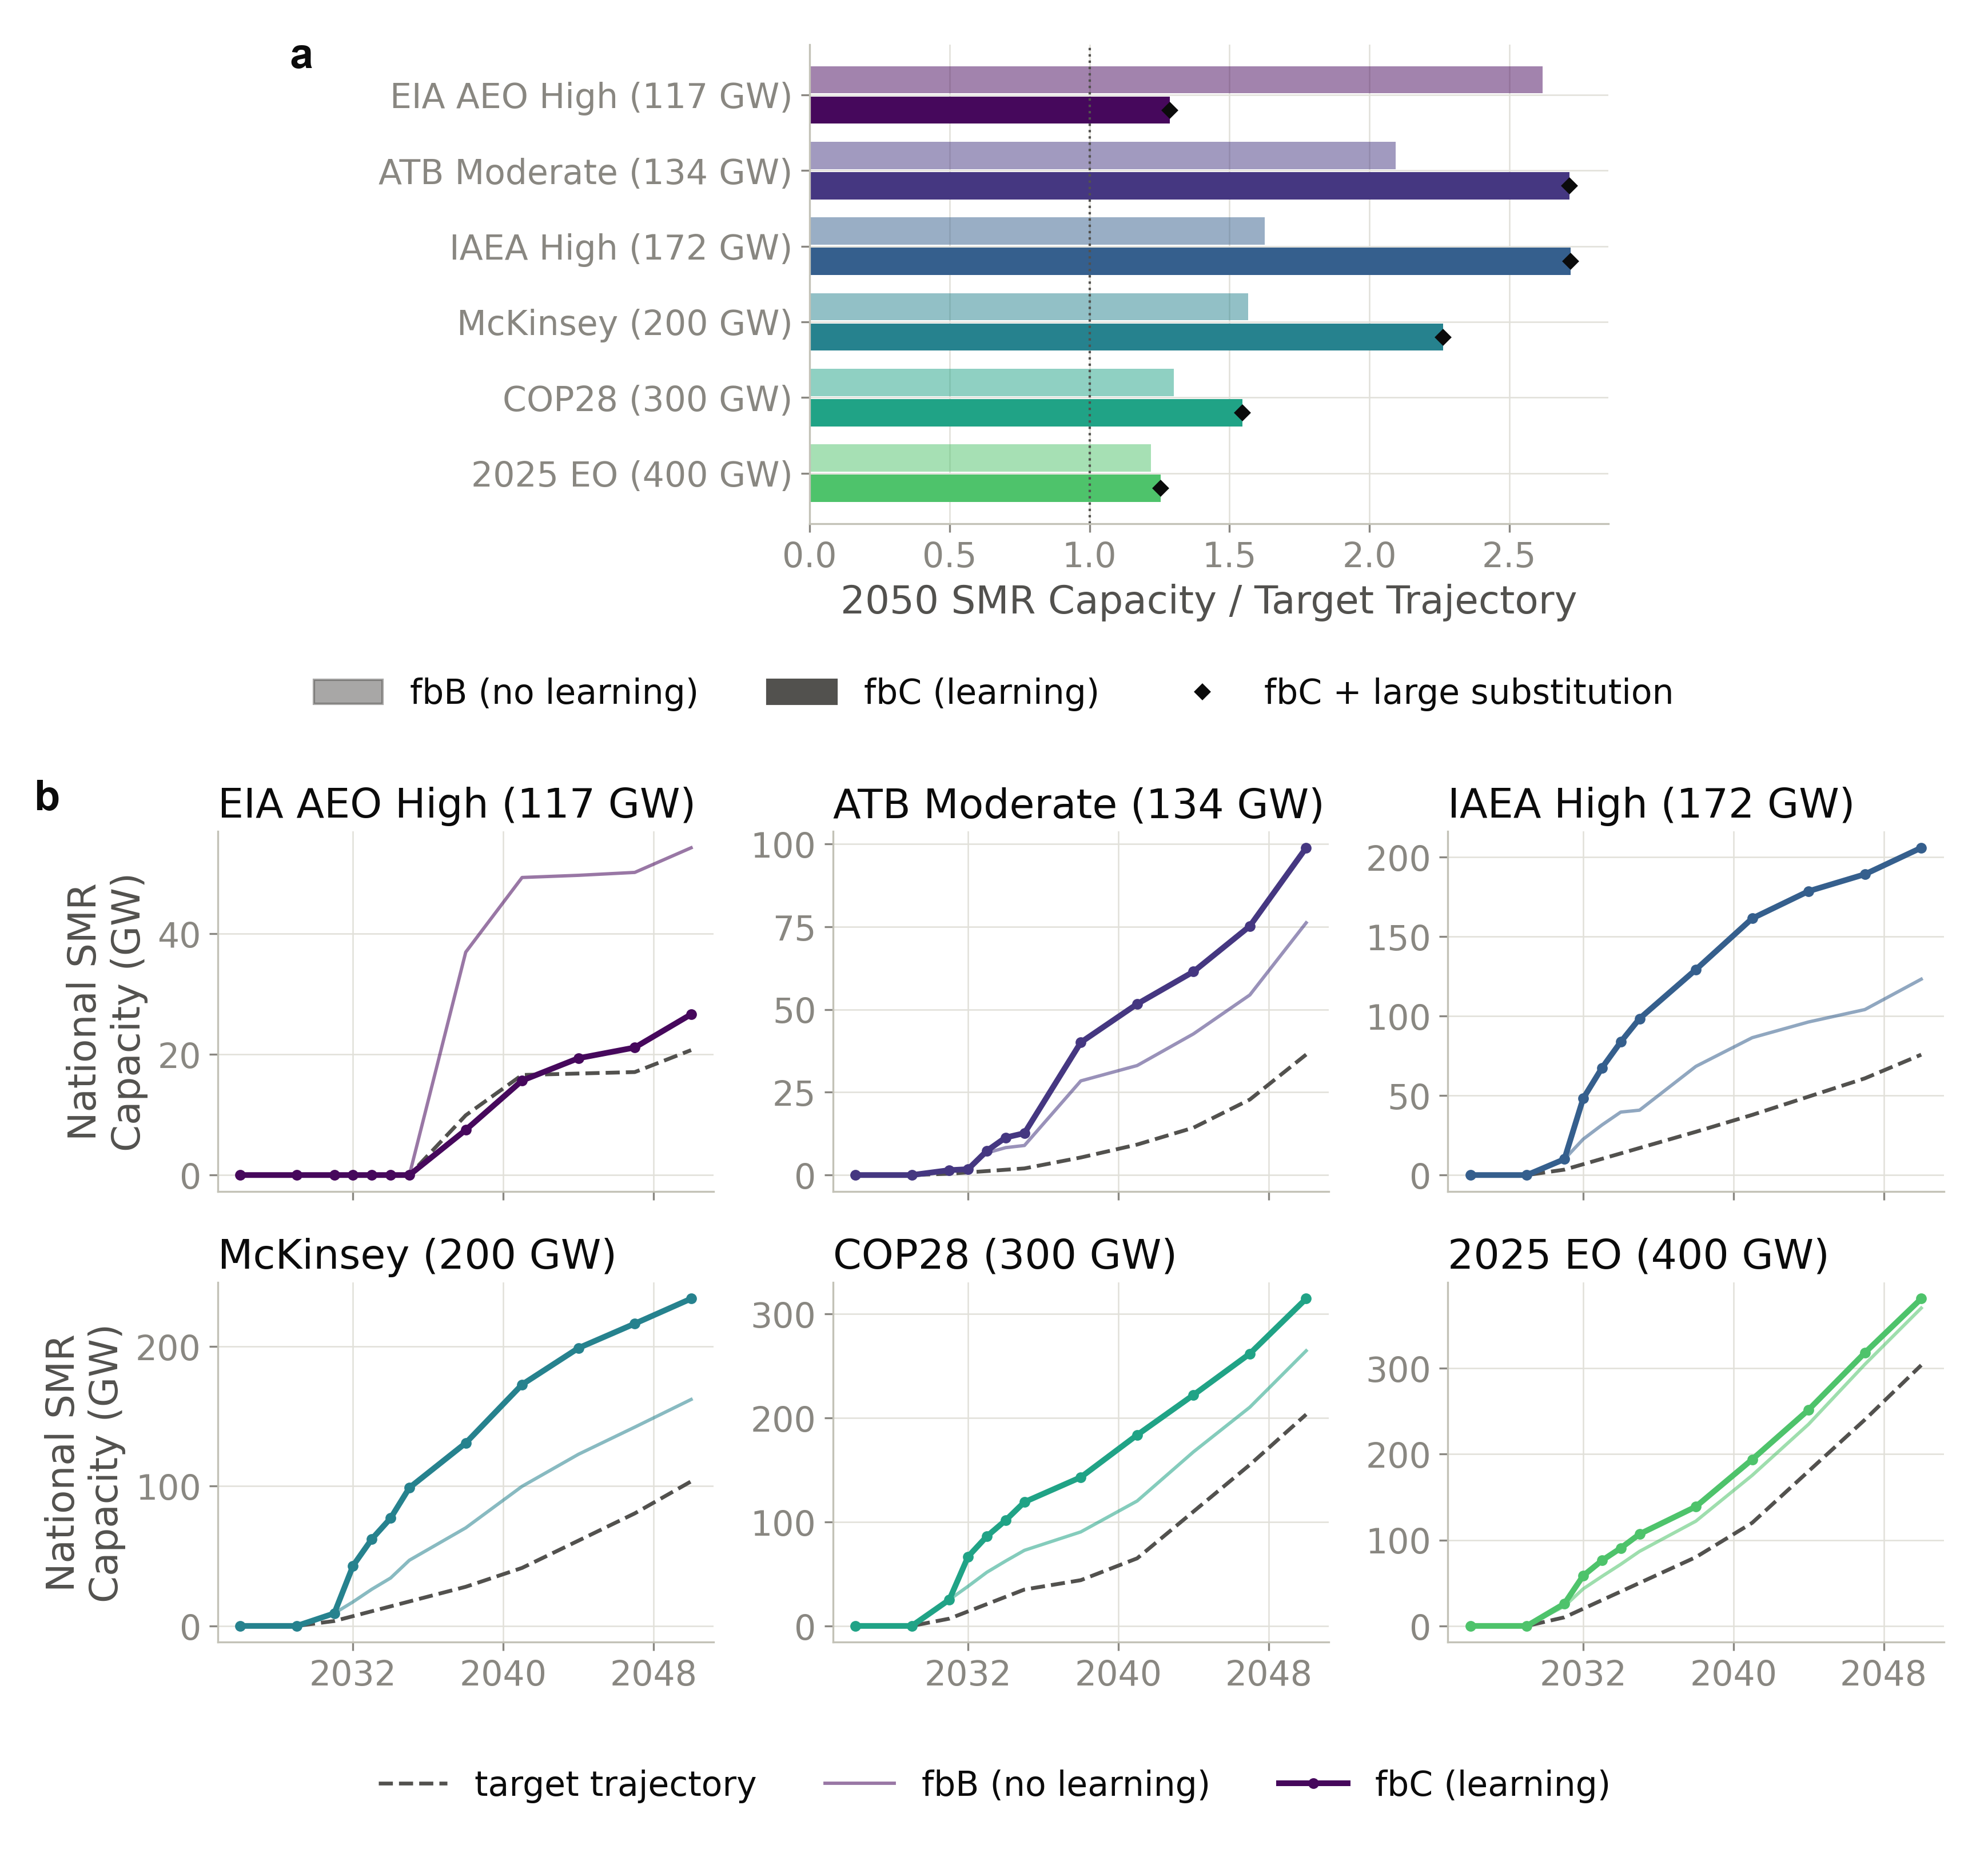

composed -> analysis\results\figures\si\SF12_cliff_and_demand_curve.png  (2001x2630 px)


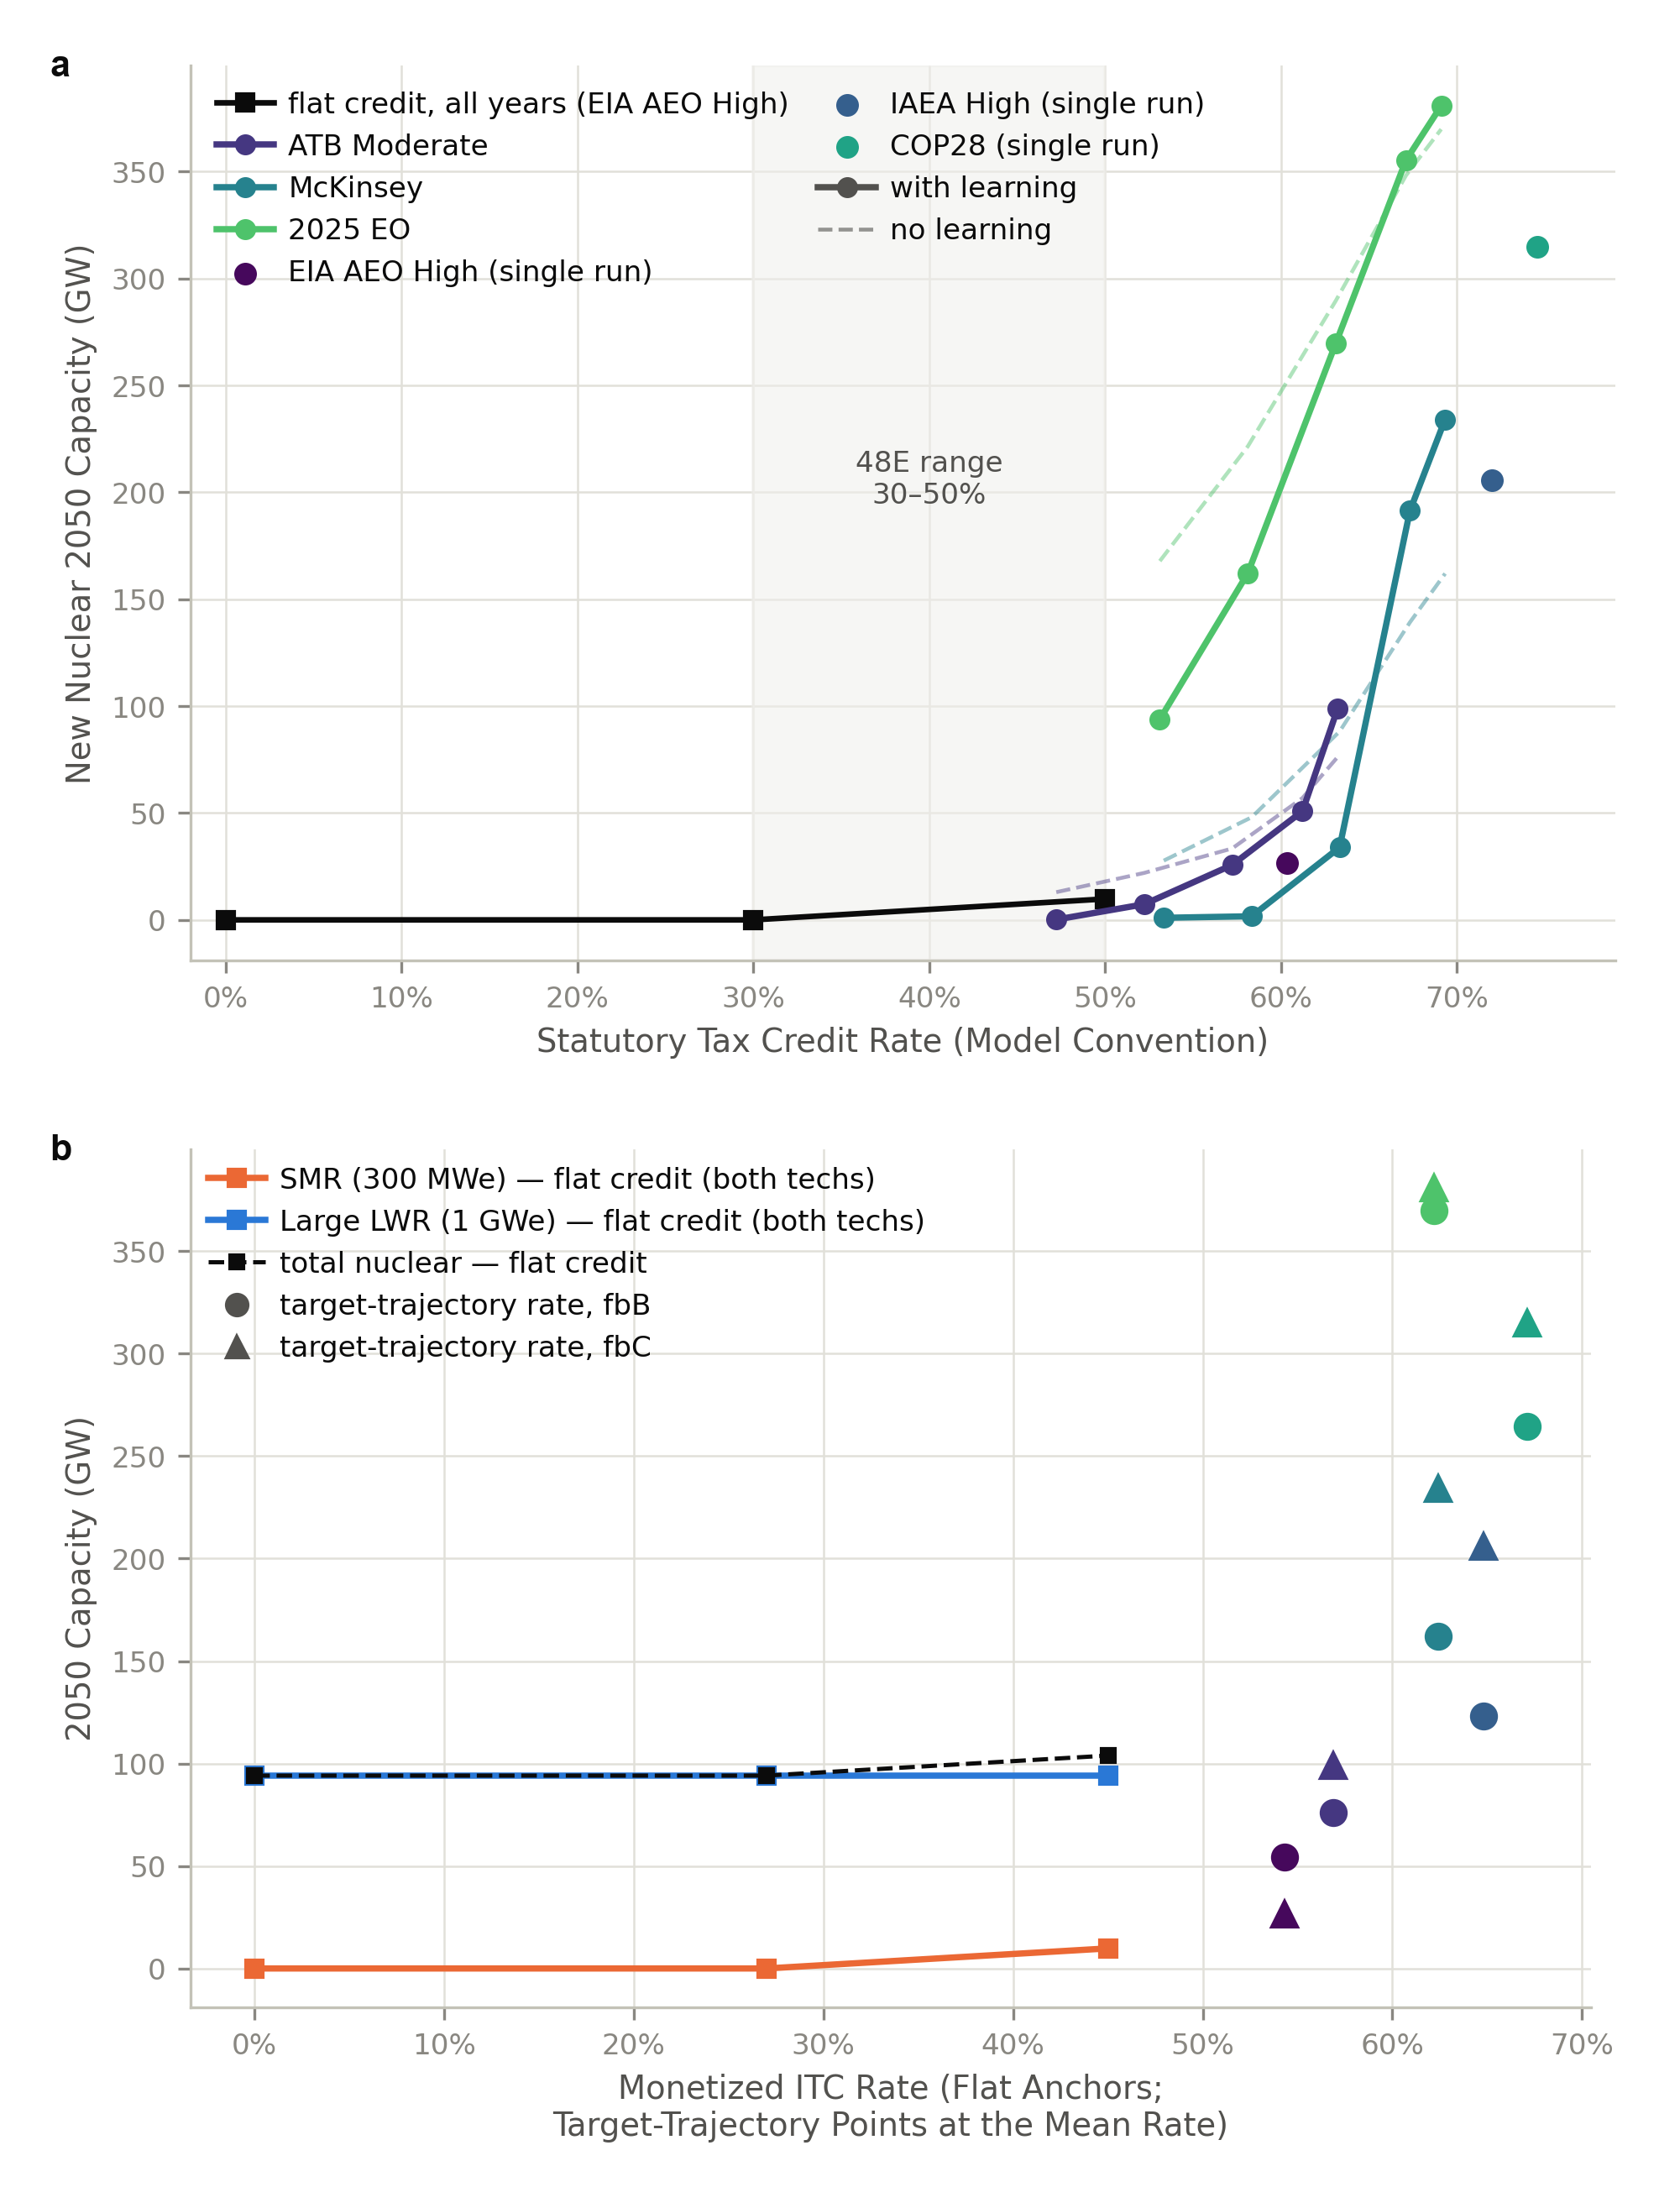

In [23]:
from nlpaper import compose
_ = compose.compose(
    [[EXP_A / "h04_delivery_summary.png"],
     [EXP_A / "h03_fbC_trajectory_panels.png"]],
    "SF11_closed_loop_delivery.png", out_dir=paths.FIGS_SI,
    letters="ab", center=True,
    letter_pt=ps.fonts(11.59)["panel_letter"],   # measured composite width (in)
)
_ = compose.compose(
    [[EXP_B / "j06_new_nuclear_cliff.png"],
     [EXP_A / "h06_deployment_vs_rate.png"]],
    "SF12_cliff_and_demand_curve.png", out_dir=paths.FIGS_SI,
    letters="ab", center=True,
    letter_pt=ps.fonts(6.67)["panel_letter"],
)

## Caveats

- **Myopic sequential solve.** ReEDS sees one solve year at a time, with costs that lag by one
  solve. The fbB control carries the same myopia, so the fbC-against-fbB contrast isolates
  learning, not foresight. The same myopia makes strict monotonicity of delivery in the rate
  unprovable, and it explains the delayed start of fbC_eia.
- **Solve years only.** The trajectory files are annual, but the model solves 12 years in
  2026-2050. Every comparison is at solve years, on cumulative all-vintage capacity, which is the
  basis the mandate counts.
- **The `eo` schedule is back-loaded.** Its fed rates rise from 2044 to 2050, so a 2050-only
  metric could hide a mid-course sag. The tiers therefore grade every rate year, and `r02` keeps
  the per-year gaps.
- **The rate axis of the curves is a mean.** Schedule credits vary by year; the mean over rate
  years is a display convention, not an instrument. The flat anchors are exact points of a
  different instrument (both technologies, all years) and bound the curve from below.
- **Tier thresholds are conventions** (5 MW; max(5%, 500 MW); 15%). They are exported with the
  data so a reader can re-cut them.
- **No shadow prices exist in the minus runs** (no mandate). Nothing here re-prices a schedule;
  the minus runs test delivery only.

In [24]:
outs = sorted(p.relative_to(paths.RESULTS).as_posix()
              for p in list(EXP_A.glob("*.*")) + list(EXP_B.glob("*.*"))) \
    + [f"figures/si/{n}" for n in ["SF11_closed_loop_delivery.png",
                                   "SF12_cliff_and_demand_curve.png"]]
print("outputs written by this notebook:")
for o in outs:
    print(" ", o)

outputs written by this notebook:
  exports/09/itcfb/fed_rate_echo.csv
  exports/09/itcfb/h03_fbC_trajectory_panels.png
  exports/09/itcfb/h04_delivery_summary.png
  exports/09/itcfb/h06_deployment_vs_rate.png
  exports/09/itcfb/q00_run_inventory.csv
  exports/09/itcfb/q01_fbA_dual_collapse.csv
  exports/09/itcfb/q02_fbB_gaps.csv
  exports/09/itcfb/q03_fbC_gaps.csv
  exports/09/itcfb/q04_s9_verdict.csv
  exports/09/itcfb/q05_fbK_calibration.csv
  exports/09/itcfb/q06_rate_deployment.csv
  exports/09/itcfb/q07_large_substitution.csv
  exports/09/itcfbm/fed_rate_echo.csv
  exports/09/itcfbm/j06_new_nuclear_cliff.png
  exports/09/itcfbm/r00_run_inventory.csv
  exports/09/itcfbm/r01_rate_ladder.csv
  exports/09/itcfbm/r02_delivery_gaps.csv
  exports/09/itcfbm/r03_minimality_verdicts.csv
  exports/09/itcfbm/r04_rate_deployment.csv
  exports/09/itcfbm/r05_ignition_cushion.csv
  exports/09/itcfbm/r06_substitution.csv
  figures/si/SF11_closed_loop_delivery.png
  figures/si/SF12_cliff_and_deman